# เตรียมข้อมูล

In [113]:
# import

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

In [114]:
# pull data from csv file
# data = pd.read_csv('bank.csv') 
data_full = pd.read_csv('bank-full.csv')

In [115]:
# check the first 5 rows of the full data
data_full.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## ข้อมูลลูกค้าธนาคาร (Bank Client Data)
1. age – อายุของลูกค้า (ข้อมูลตัวเลข)
2. job – ประเภทอาชีพของลูกค้า (ข้อมูลหมวดหมู่)
   - admin. = พนักงานธุรการ
   - unknown = ไม่ทราบอาชีพ
   - unemployed = ว่างงาน
   - management = ผู้บริหาร / ผู้จัดการ
   - housemaid = แม่บ้าน
   - entrepreneur = ผู้ประกอบการ / เจ้าของธุรกิจ
   - student = นักเรียน / นักศึกษา
   - blue-collar = ผู้ใช้แรงงาน
   - self-employed = ประกอบอาชีพอิสระ
   - retired = เกษียณอายุ
   - technician = ช่างเทคนิค
   - services = พนักงานบริการ
3. marital – สถานภาพสมรส
   - married = สมรส
   - divorced = หย่าร้าง หรือคู่สมรสเสียชีวิต
   - single = โสด
4. education – ระดับการศึกษา
   - unknown = ไม่ทราบ
   - secondary = มัธยมศึกษา
   - primary = ประถมศึกษา
   - tertiary = อุดมศึกษา / ระดับมหาวิทยาลัย
5. default – มีประวัติผิดนัดชำระหนี้หรือไม่
   - yes = มี
   - no = ไม่มี
6. balance – ยอดเงินคงเหลือเฉลี่ยรายปี (หน่วยยูโร)
7. housing – มีสินเชื่อที่อยู่อาศัยหรือไม่
   - yes = มี
   - no = ไม่มี
8. loan – มีสินเชื่อส่วนบุคคลหรือไม่
   - yes = มี
   - no = ไม่มี
9. contact – ประเภทช่องทางการติดต่อลูกค้า
   - unknown = ไม่ทราบช่องทาง
   - telephone = โทรศัพท์พื้นฐาน
   - cellular = โทรศัพท์มือถือ
10. day – วันที่ติดต่อลูกค้าครั้งล่าสุด (วันที่ของเดือน)
11. month – เดือนที่ติดต่อลูกค้าครั้งล่าสุด
- jan = มกราคม
- feb = กุมภาพันธ์
- mar = มีนาคม
- apr = เมษายน
- may = พฤษภาคม
- jun = มิถุนายน
- jul = กรกฎาคม
- aug = สิงหาคม
- sep = กันยายน
- oct = ตุลาคม
- nov = พฤศจิกายน
- dec = ธันวาคม
12. duration – ระยะเวลาที่ติดต่อลูกค้าครั้งล่าสุด (หน่วยวินาที)
13. campaign – จำนวนครั้งที่ติดต่อลูกค้าในแคมเปญปัจจุบัน (รวมการติดต่อล่าสุด)
14. pdays – จำนวนวันที่ผ่านไปนับจากการติดต่อลูกค้าครั้งล่าสุดในแคมเปญก่อนหน้า
- -1 = ไม่เคยติดต่อลูกค้ามาก่อน
15. previous – จำนวนครั้งที่เคยติดต่อลูกค้าก่อนแคมเปญปัจจุบัน
16. poutcome – ผลลัพธ์ของแคมเปญการตลาดครั้งก่อน
- unknown = ไม่ทราบผลลัพธ์
- other = ผลลัพธ์อื่น ๆ
- failure = ไม่ประสบความสำเร็จ
- success = ประสบความสำเร็จ
17. y – ลูกค้าสมัครใช้บริการเงินฝากประจำ (Term Deposit) หรือไม่
- yes = สมัครเงินฝากประจำ
- no = ไม่สมัครเงินฝากประจำ

In [116]:
# check the shape of the data
print("Shape of the full data:", data_full.shape)

Shape of the full data: (45211, 17)


In [117]:
# check type of data
print(data_full.dtypes)

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


# ส่วนที่ 1: Exploratory Data Analysis

## Distribution of Duration
จงวิเคราะห์การกระจายของตัวแปร duration โดยใช้ Histogram และ Boxplot พร้อมอธิบายลักษณะการกระจายของข้อมูลว่ามีความเบ้ (Skewness) หรือค่าผิดปกติ (Outliers) หรือไม่

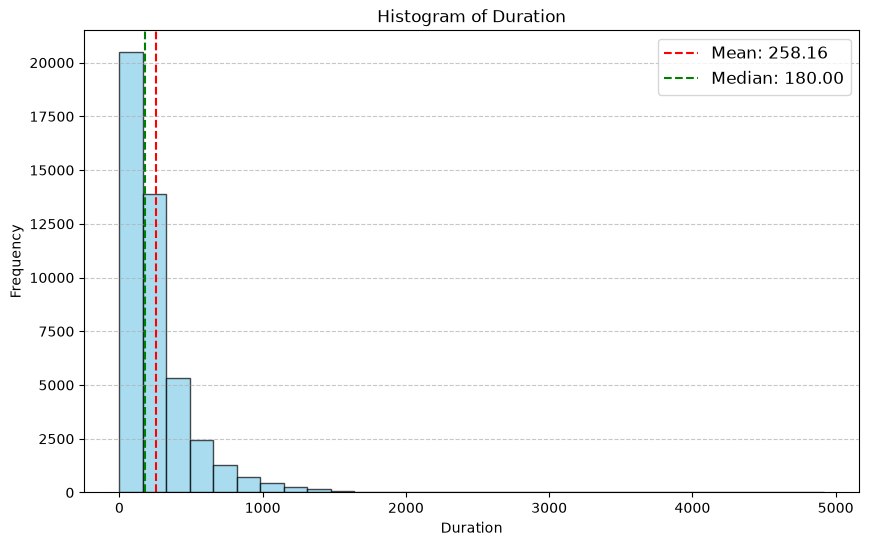

In [118]:
# create Histogram of duration
plt.figure(figsize=(10, 6))
plt.hist(data_full['duration'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Duration')
plt.xlabel('Duration')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add annotations
mean_value = data_full['duration'].mean()
median_value = data_full['duration'].median()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_value:.2f}')
plt.axvline(median_value, color='green', linestyle='dashed', linewidth=1.5, label=f'Median: {median_value:.2f}')
plt.legend(fontsize=12)
plt.show()

C:\Users\Maru\AppData\Local\Temp\ipykernel_25468\3741894565.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


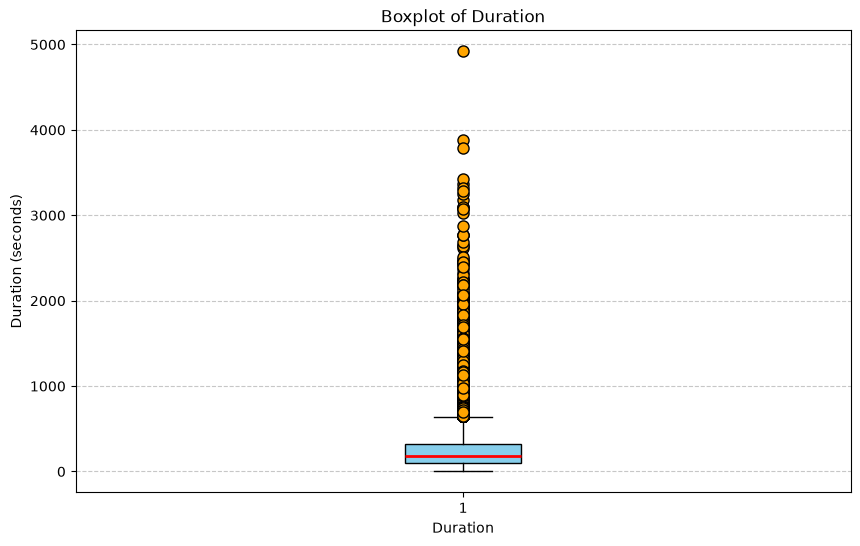

,Total,Median,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers,Outlier (%)
0,45211,180.0,103.0,319.0,216.0,-221.0,643.0,3235,7.16


In [119]:
# create Boxplot of duration

# Select duration data
duration = data_full['duration'].dropna()

# Calculate statistics
median = duration.median()
Q1 = duration.quantile(0.25)
Q3 = duration.quantile(0.75)
IQR = Q3 - Q1

# Calculate outlier boundaries (IQR Method)
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

# Identify outliers
outliers = duration[
    (duration < lower_fence) |
    (duration > upper_fence)
]

outlier_count = len(outliers)
outlier_pct = (outlier_count / len(duration)) * 100

# Create Boxplot of Duration
plt.figure(figsize=(10, 6))

plt.boxplot(
    duration,
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="skyblue", color="black"),
    medianprops=dict(color="red", linewidth=2),
    whiskerprops=dict(color="black", linewidth=1),
    capprops=dict(color="black", linewidth=1),
    flierprops=dict(
        markerfacecolor="orange",
        markeredgecolor="black",
        marker="o",
        markersize=8
    )
)

plt.title('Boxplot of Duration')
plt.xlabel('Duration')
plt.ylabel('Duration (seconds)')
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

# Create statistics summary
summary = pd.DataFrame({
    'Total': [len(duration)],
    'Median': [median],
    'Q1': [Q1],
    'Q3': [Q3],
    'IQR': [IQR],
    'Lower Fence': [lower_fence],
    'Upper Fence': [upper_fence],
    'Outliers': [outlier_count],
    'Outlier (%)': [outlier_pct]
})

# Display results
display(summary.round(2))


## Duration vs Target
จงเปรียบเทียบการกระจายของตัวแปร duration ระหว่างกลุ่มลูกค้าที่สมัคร (y = yes) และไม่สมัคร (y = no) โดยใช้ Boxplot หรือ Violin Plot พร้อมสรุปข้อค้นพบ (Insights) จากการเปรียบเทียบ

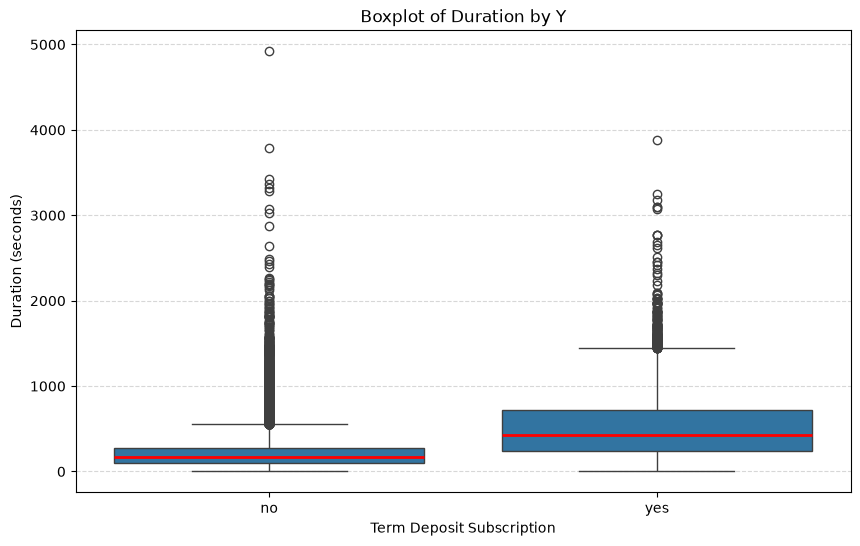

,Term Deposit,Total,Median,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers,Outlier (%)
0,no,39922,164.0,95.0,279.0,184.0,-181.0,555.0,2384,5.97
1,yes,5289,426.0,244.0,725.0,481.0,-477.5,1446.5,167,3.16


In [120]:
# Boxplot of Duration by Y
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data_full,
    x='y',
    y='duration',
    order=['no', 'yes'],
    medianprops=dict(color='red', linewidth=2)
)

plt.title('Boxplot of Duration by Y')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Duration (seconds)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# คำนวณ Outliers ด้วย IQR แยกตามกลุ่ม
results = []

for group in ['no', 'yes']:

    duration = data_full.loc[
        data_full['y'] == group, 'duration'
    ]

    Q1 = duration.quantile(0.25)
    Q3 = duration.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = duration[
        (duration < lower) | (duration > upper)
    ]

    results.append({
        'Term Deposit': group,
        'Total': len(duration),
        'Median': duration.median(),
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Fence': lower,
        'Upper Fence': upper,
        'Outliers': len(outliers),
        'Outlier (%)': len(outliers) / len(duration) * 100
    })

outlier_summary = pd.DataFrame(results)

display(outlier_summary.round(2))


## Categorical Variables Exploration
จงวิเคราะห์ตัวแปรเชิงหมวดหมู่ (Categorical Variables) ได้แก่ job, marital และ education โดยใช้ Countplot และ Barplot พร้อมอธิบายว่ากลุ่มลูกค้าใดมีอัตราการสมัคร Term Deposit สูงกว่าค่าเฉลี่ยโดยรวม

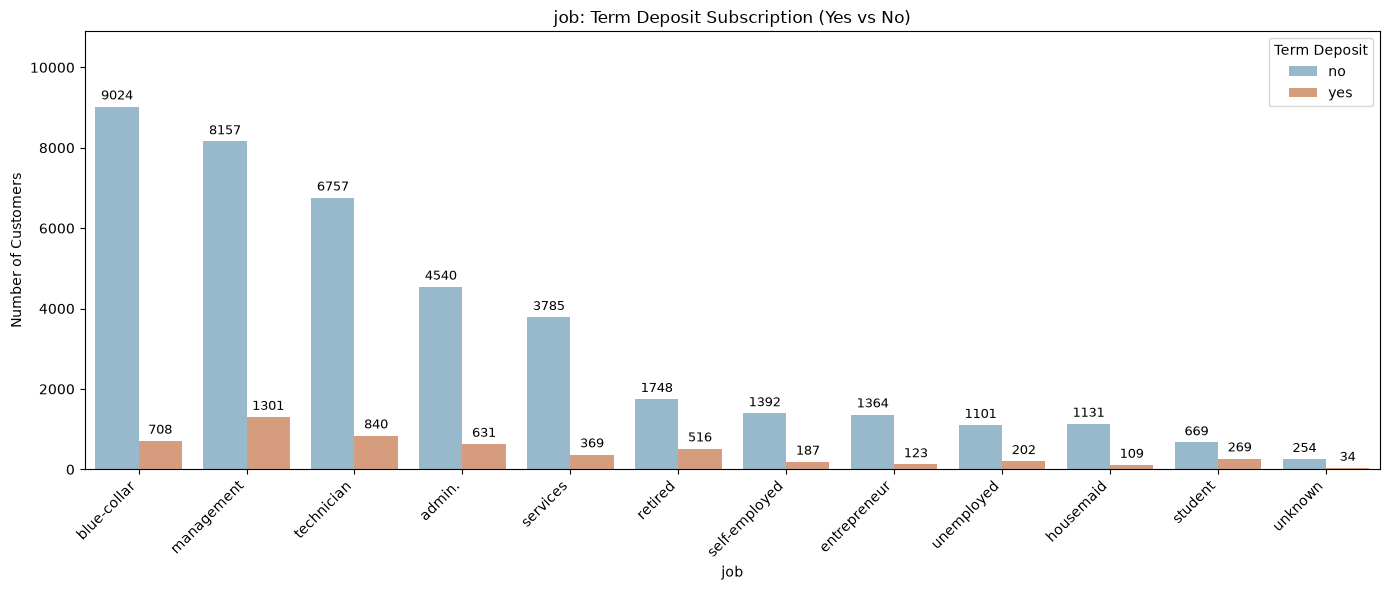

JOB: Subscription Count


y,no,yes,total,rate_pct
job,,,,
blue-collar,9024,708,9732,7.27
management,8157,1301,9458,13.76
technician,6757,840,7597,11.06
admin.,4540,631,5171,12.20
services,3785,369,4154,8.88
retired,1748,516,2264,22.79
self-employed,1392,187,1579,11.84
entrepreneur,1364,123,1487,8.27
unemployed,1101,202,1303,15.50


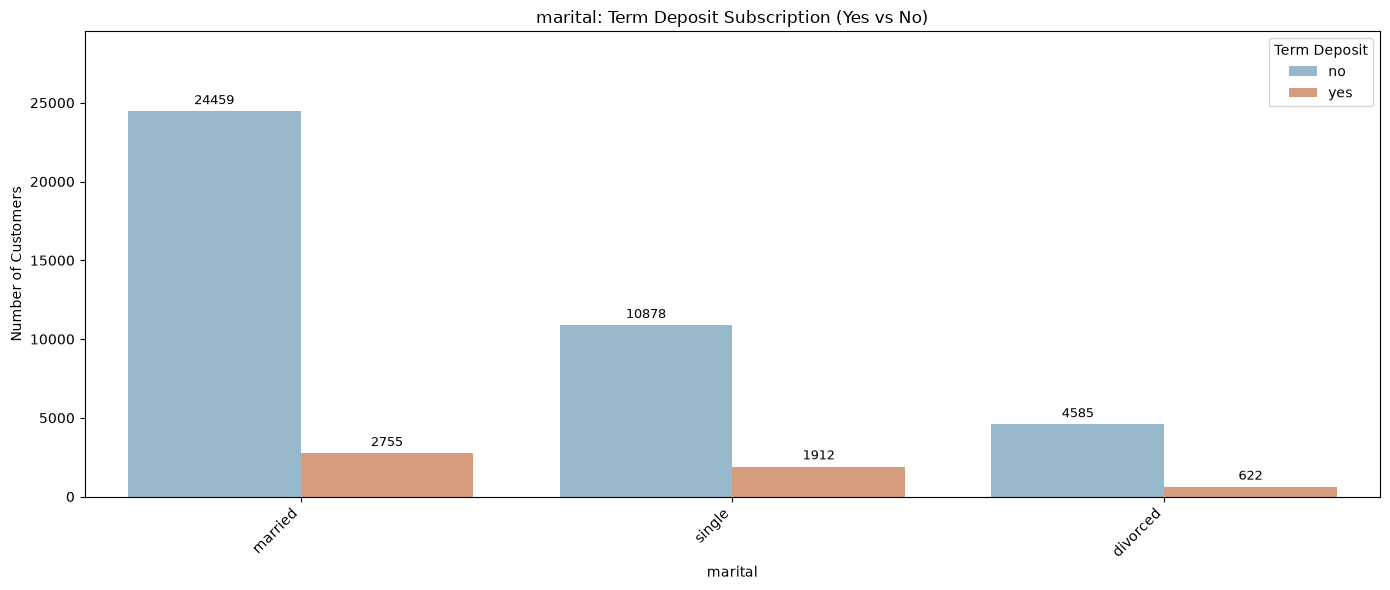

MARITAL: Subscription Count


y,no,yes,total,rate_pct
marital,,,,
married,24459,2755,27214,10.12
single,10878,1912,12790,14.95
divorced,4585,622,5207,11.95


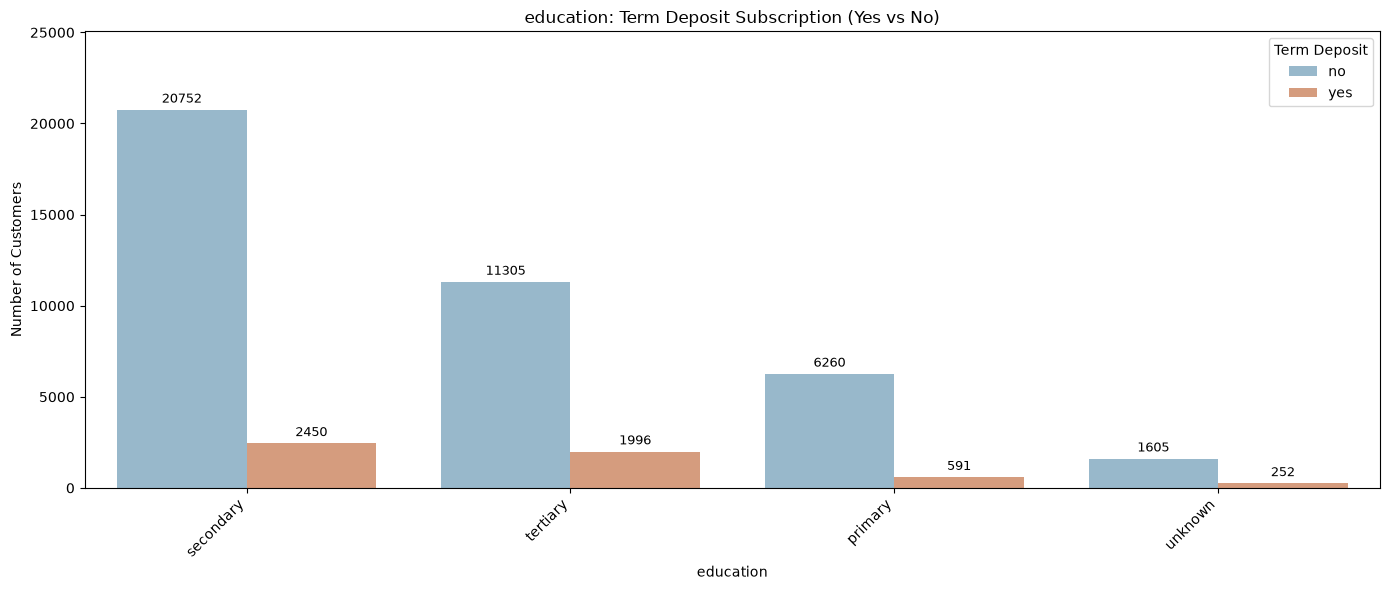

EDUCATION: Subscription Count


y,no,yes,total,rate_pct
education,,,,
secondary,20752,2450,23202,10.56
tertiary,11305,1996,13301,15.01
primary,6260,591,6851,8.63
unknown,1605,252,1857,13.57


In [121]:

import matplotlib.pyplot as plt
import seaborn as sns

# Countplot: Term Deposit Yes / No
for col in ['job', 'marital', 'education']:

    # เรียงกลุ่มตามจำนวนลูกค้าทั้งหมด
    order = data_full[col].value_counts().index

    plt.figure(figsize=(14, 6))

    ax = sns.countplot(
        data=data_full,
        x=col,
        hue='y',
        hue_order=['no', 'yes'],
        order=order,
        palette={'no': '#8fbad4', 'yes': '#e39770'}
    )

    # เพิ่มจำนวนคนบนแต่ละแท่งกราฟ
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.0f',
            padding=3,
            fontsize=9
        )

    ax.set_title(f'{col}: Term Deposit Subscription (Yes vs No)')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Customers')
    ax.legend(title='Term Deposit')

    # เพิ่มพื้นที่ด้านบนสำหรับตัวเลข
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)

    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # ตารางสรุปจำนวนลูกค้าสมัครและไม่สมัคร
    print(f'{col.upper()}: Subscription Count')

    summary = (
        data_full.groupby([col, 'y'])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=['no', 'yes'], fill_value=0)
    )

    summary['total'] = summary['no'] + summary['yes']
    summary['rate_pct'] = (
        summary['yes'] / summary['total'] * 100
    ).round(2)

    display(summary.sort_values('total', ascending=False))


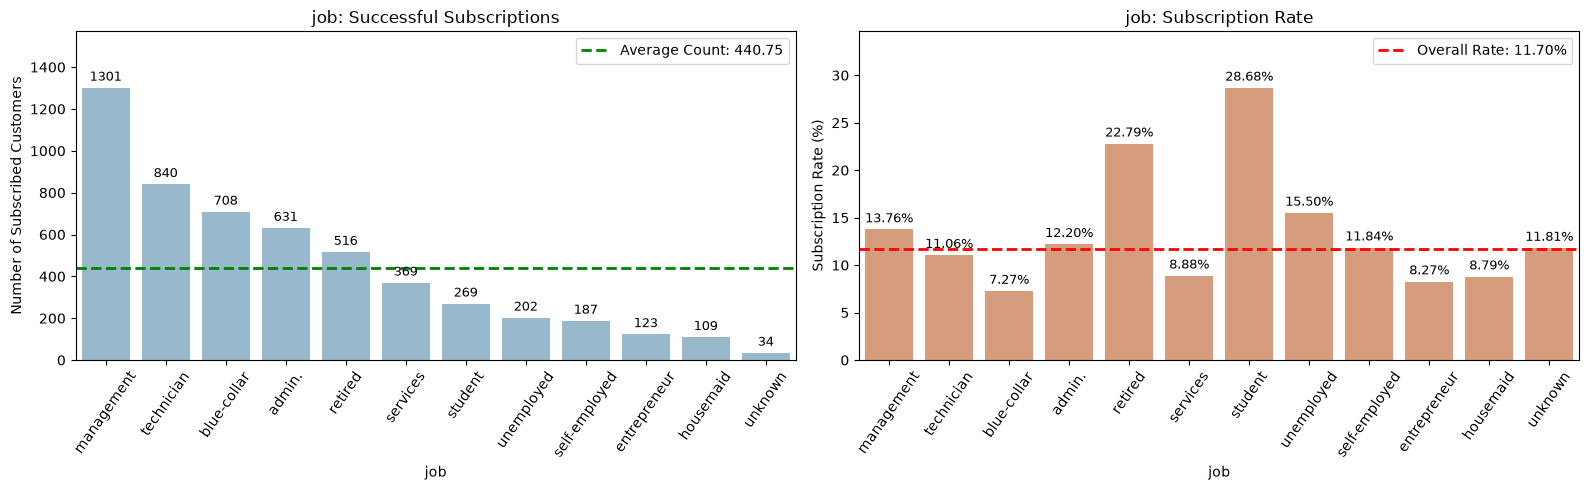


JOB
Average Count: 440.75
Overall Subscription Rate: 11.70%
Groups Above Overall Subscription Rate:


,subscribed,total,rate_pct
job,,,
student,269,938,28.68
retired,516,2264,22.79
unemployed,202,1303,15.50
management,1301,9458,13.76
admin.,631,5171,12.20
self-employed,187,1579,11.84
unknown,34,288,11.81


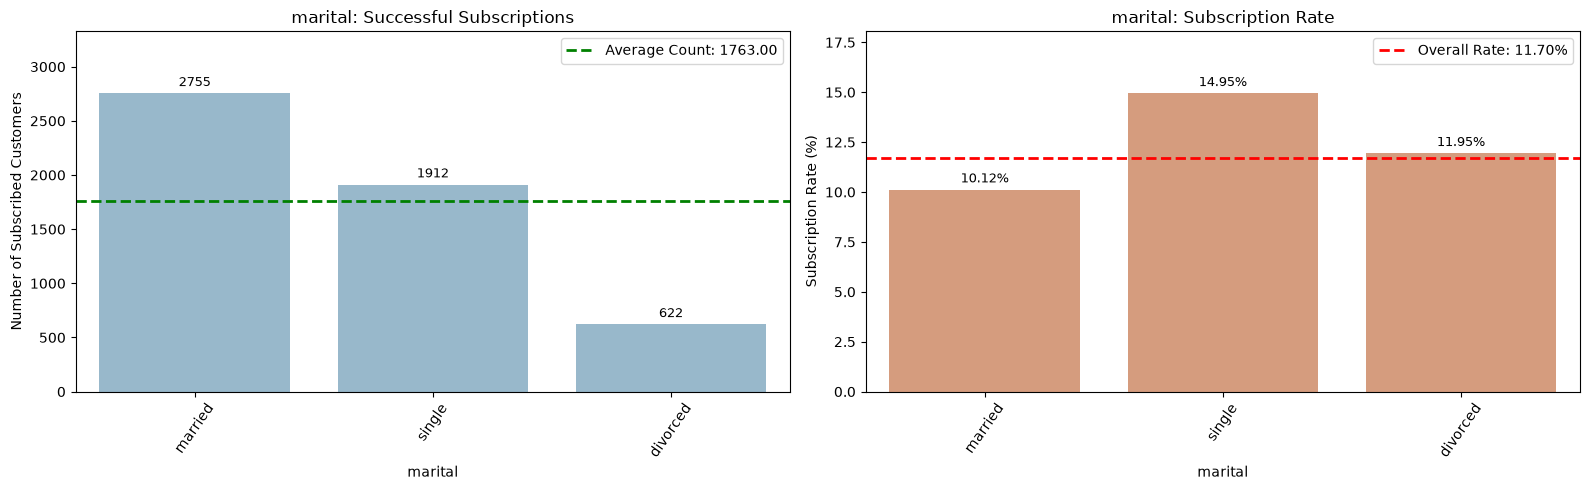


MARITAL
Average Count: 1763.00
Overall Subscription Rate: 11.70%
Groups Above Overall Subscription Rate:


,subscribed,total,rate_pct
marital,,,
single,1912,12790,14.95
divorced,622,5207,11.95


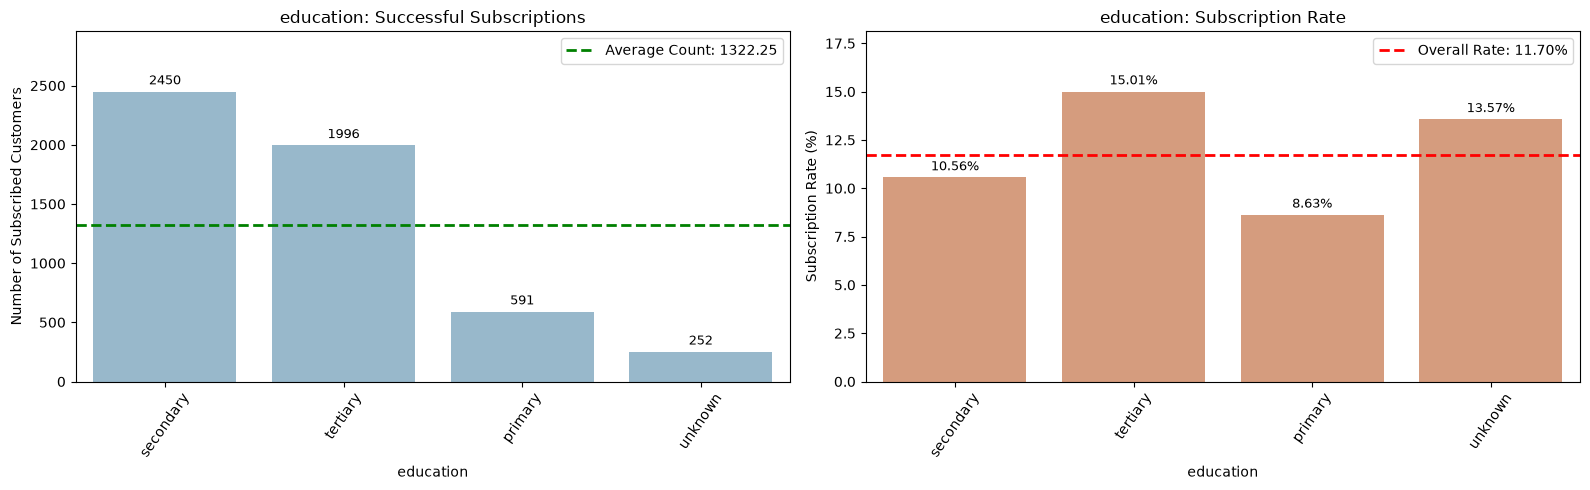


EDUCATION
Average Count: 1322.25
Overall Subscription Rate: 11.70%
Groups Above Overall Subscription Rate:


,subscribed,total,rate_pct
education,,,
tertiary,1996,13301,15.01
unknown,252,1857,13.57


In [122]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# แปลงผลการสมัคร Term Deposit
data_full['subscribed'] = (data_full['y'] == 'yes').astype(int)

# ฟังก์ชันคำนวณอัตราการสมัครตามกลุ่ม
def rates_by(col):
    result = data_full.groupby(col)['subscribed'].agg(
        total='count',
        subscribed='sum',
        rate='mean'
    )
    result['rate_pct'] = result['rate'] * 100
    return result

# ค่าเฉลี่ยอัตราการสมัครของลูกค้าทั้งหมด
overall = 100 * data_full['subscribed'].mean()

# คัดเฉพาะลูกค้าที่สมัคร Term Deposit สำเร็จ
df_yes = data_full[data_full['subscribed'] == 1].copy()

for col in ['job', 'marital', 'education']:

    # เรียงตามจำนวนลูกค้าที่สมัครสำเร็จ
    order = df_yes[col].value_counts().index

    fig, ax = plt.subplots(1, 2, figsize=(16, 5))

    # =====================================
    # กราฟซ้าย: Countplot
    # =====================================
    sns.countplot(
        data=df_yes,
        x=col,
        order=order,
        ax=ax[0],
        color='#8fbad4'
    )

    ax[0].set_title(f'{col}: Successful Subscriptions')
    ax[0].set_xlabel(col)
    ax[0].set_ylabel('Number of Subscribed Customers')

    # แสดงจำนวนคนบนแท่งกราฟ
    for container in ax[0].containers:
        ax[0].bar_label(
            container,
            fmt='%.0f',
            padding=3,
            fontsize=9
        )

    # เส้นค่าเฉลี่ยจำนวนคนที่สมัครสำเร็จต่อกลุ่ม
    mean_count = df_yes[col].value_counts().mean()

    ax[0].axhline(
        y=mean_count,
        color='green',
        linestyle='--',
        linewidth=2,
        label=f'Average Count: {mean_count:.2f}'
    )

    ax[0].legend()
    ax[0].set_ylim(0, ax[0].get_ylim()[1] * 1.15)

    # =====================================
    # กราฟขวา: Barplot
    # =====================================
    r = rates_by(col).reindex(order)

    sns.barplot(
        x=r.index,
        y=r['rate_pct'].values,
        ax=ax[1],
        color='#e39770',
        errorbar=None
    )

    ax[1].set_title(f'{col}: Subscription Rate')
    ax[1].set_xlabel(col)
    ax[1].set_ylabel('Subscription Rate (%)')

    # แสดงเปอร์เซ็นต์บนแท่งกราฟ
    for container in ax[1].containers:
        ax[1].bar_label(
            container,
            fmt='%.2f%%',
            padding=3,
            fontsize=9
        )

    # เส้นค่าเฉลี่ยอัตราการสมัครของลูกค้าทั้งหมด
    ax[1].axhline(
        y=overall,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f'Overall Rate: {overall:.2f}%'
    )

    ax[1].legend()
    ax[1].set_ylim(0, ax[1].get_ylim()[1] * 1.15)

    # ปรับแกน X
    for a in ax:
        a.tick_params(axis='x', rotation=55)

    plt.tight_layout()
    plt.show()

    # =====================================
    # แสดงกลุ่มที่มีอัตราสมัครสูงกว่าค่าเฉลี่ย
    # =====================================
    print(f'\n{col.upper()}')
    print(f'Average Count: {mean_count:.2f}')
    print(f'Overall Subscription Rate: {overall:.2f}%')
    print('Groups Above Overall Subscription Rate:')

    display(
        rates_by(col)
        .query('rate_pct > @overall')
        [['subscribed', 'total', 'rate_pct']]
        .sort_values('rate_pct', ascending=False)
        .round(2)
    )


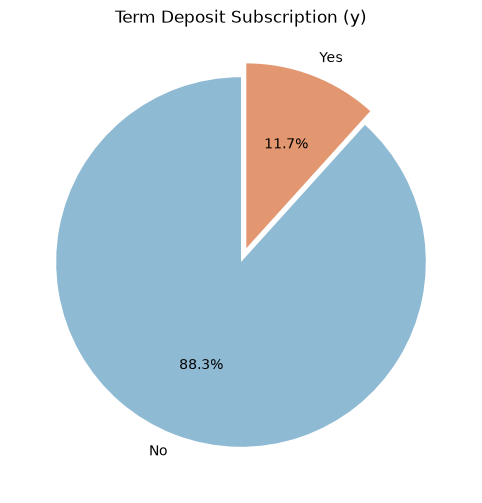

In [123]:
import matplotlib.pyplot as plt

# นับจำนวนลูกค้าแต่ละกลุ่ม
counts = data_full['y'].value_counts()

# สร้าง pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts,
    labels=['No', 'Yes'],   # ถ้า value_counts ออก no ก่อน yes
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8fbad4', '#e39770'],
    explode=(0, 0.08)
)

plt.title('Term Deposit Subscription (y)')
plt.show()

## Correlation Matrix
จงสร้างเมทริกซ์สหสัมพันธ์ (Correlation Matrix) สำหรับตัวแปรเชิงตัวเลข (Numeric Variables) ได้แก่ age, balance, campaign, pdays, previous และ duration โดยแสดงผลด้วย Heatmap พร้อมวิเคราะห์และตีความความสัมพันธ์ที่สำคัญระหว่างตัวแปร

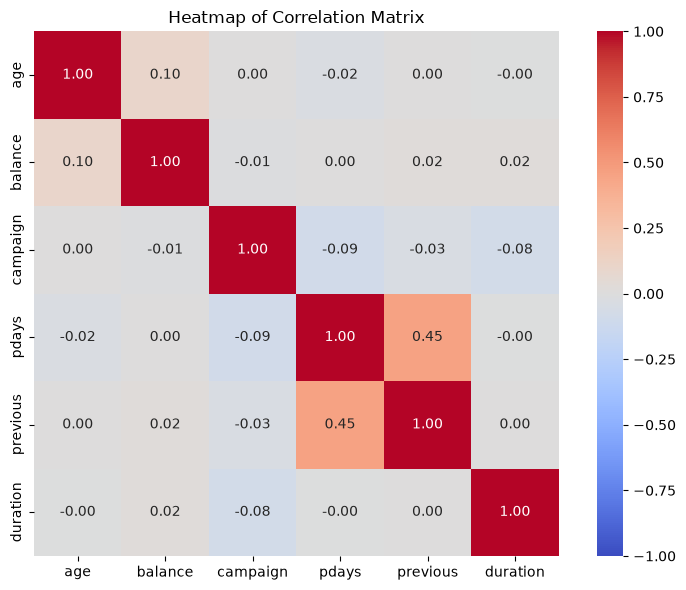

Top absolute correlations:


Pearson r
pdays    previous   0.454820
age      balance    0.097783
campaign pdays     -0.088628
         duration  -0.084570
         previous  -0.032855
age      pdays     -0.023758
balance  duration   0.021560
         previous   0.016674

In [124]:
# create heatmap of age, balance, campaign, pdays, previous and duration
plt.figure(figsize=(8, 6))
correlation_matrix = data_full[['age', 'balance', 'campaign', 'pdays', 'previous', 'duration']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f',center=0, vmin=-1, vmax=1, square=True)
plt.title('Heatmap of Correlation Matrix')
plt.tight_layout()
plt.show()
pairs = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape),1).astype(bool)).stack().sort_values(key=abs,ascending=False)
print('Top absolute correlations:'); display(pairs.head(8).rename('Pearson r').to_frame())

## Temporal Pattern Analysis
จงวิเคราะห์รูปแบบการสมัคร Term Deposit (y) ตามตัวแปร month และ day โดยใช้ Lineplot หรือ Barplot พร้อมอธิบายว่ามีรูปแบบตามฤดูกาล (Seasonality) หรือช่วงเวลาที่ลูกค้ามีอัตราการสมัครสูงเป็นพิเศษหรือไม่

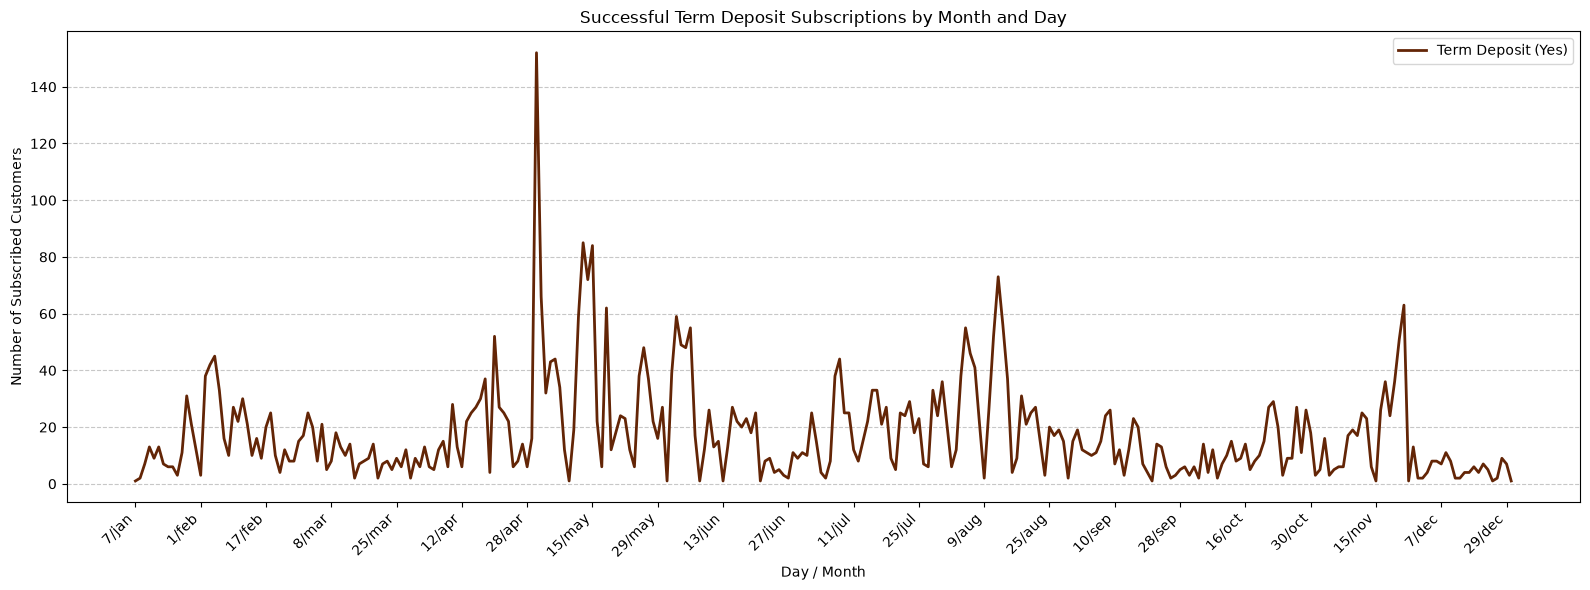

Top 5 Peak Subscription Dates:


,Day / Month,Subscriptions
86,30/apr,152
96,13/may,85
98,15/may,84
185,12/aug,73
97,14/may,72


In [125]:
# create line plot of Term Depositby by month and day



# กรองเฉพาะลูกค้าที่สมัคร Term Deposit สำเร็จ
df_yes = data_full[data_full['y'] == 'yes'].copy()

# กำหนดลำดับเดือน
months = ['jan', 'feb', 'mar', 'apr', 'may', 'jun',
          'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

# นับจำนวนผู้สมัครตามเดือนและวันที่
term_deposit_counts = (
    df_yes.groupby(['month', 'day'])
    .size()
    .reset_index(name='count')
)

# แปลงเดือนเป็นตัวเลขเพื่อเรียงลำดับ
term_deposit_counts['month_num'] = (
    term_deposit_counts['month'].map(
        {month: i + 1 for i, month in enumerate(months)}
    )
)

# เรียงตามเดือนและวันที่
term_deposit_counts = term_deposit_counts.sort_values(
    ['month_num', 'day']
).reset_index(drop=True)

# สร้างข้อความวันที่/เดือน
term_deposit_counts['date_label'] = (
    term_deposit_counts['day'].astype(str) + '/' +
    term_deposit_counts['month']
)

# สร้างกราฟ Lineplot
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    term_deposit_counts['date_label'],
    term_deposit_counts['count'],
    color="#632506",
    linewidth=2,
    label='Term Deposit (Yes)'
)

# เลือกจุดพีคสูงสุด 5 จุด
peaks = term_deposit_counts.nlargest(5, 'count')

# กำหนดจำนวนวันที่แสดงบนแกน X
step = max(1, len(term_deposit_counts) // 20)
tick_positions = range(0, len(term_deposit_counts), step)

ax.set_xticks(list(tick_positions))
ax.set_xticklabels(
    term_deposit_counts['date_label'].iloc[list(tick_positions)],
    rotation=45,
    ha='right'
)

ax.set_title('Successful Term Deposit Subscriptions by Month and Day')
ax.set_xlabel('Day / Month')
ax.set_ylabel('Number of Subscribed Customers')
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend()

plt.tight_layout()
plt.show()

# แสดงตารางจุดพีคสูงสุด 5 อันดับ
print("Top 5 Peak Subscription Dates:")
display(
    peaks[['date_label', 'count']]
    .rename(columns={
        'date_label': 'Day / Month',
        'count': 'Subscriptions'
    })
)


## Balance Distribution
จงวิเคราะห์การกระจายของตัวแปร balance โดยใช้ Histogram และ Boxplot พร้อมเปรียบเทียบว่าลูกค้าที่มียอดเงินคงเหลือสูงหรือต่ำมีแนวโน้มสมัคร Term Deposit แตกต่างกันหรือไม่

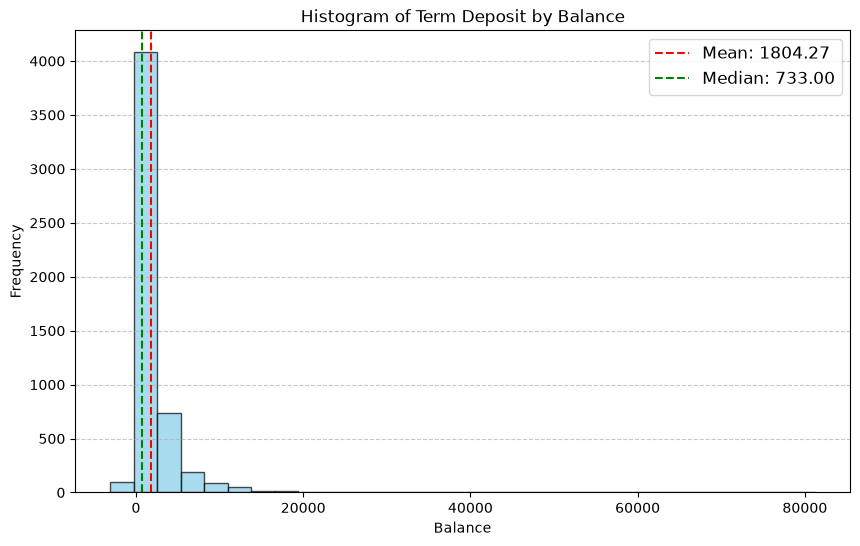

In [126]:
# create Histogram of Term Deposit by balance
plt.figure(figsize=(10, 6))
# Filter the data for term deposits (y == 'yes')
term_deposit_data = data_full[data_full['y'] == 'yes']
plt.hist(term_deposit_data['balance'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Term Deposit by Balance')
plt.xlabel('Balance')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
# Add annotations
mean_balance = term_deposit_data['balance'].mean()
median_balance = term_deposit_data['balance'].median()
plt.axvline(mean_balance, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_balance:.2f}')
plt.axvline(median_balance, color='green', linestyle='dashed', linewidth=1.5, label=f'Median: {median_balance:.2f}')

plt.legend(fontsize=12)
plt.show()

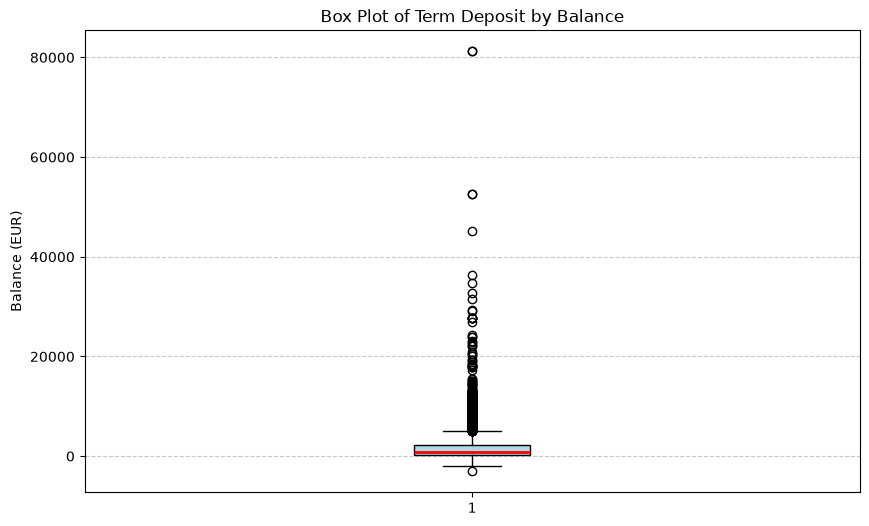

,Term Deposit,Total,Median,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers,Outlier (%)
0,Yes,5289,733.0,210.0,2159.0,1949.0,-2713.5,5082.5,427,8.07


In [127]:
# create Box Plot of Term Deposit by balance

# Filter data for successful Term Deposit (y == 'yes')
term_deposit_data = data_full[data_full['y'] == 'yes']

# Select balance
balance = term_deposit_data['balance'].dropna()

# Calculate statistics
median = balance.median()
Q1 = balance.quantile(0.25)
Q3 = balance.quantile(0.75)
IQR = Q3 - Q1

# Calculate outlier boundaries (IQR Method)
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

# Identify outliers
outliers = balance[
    (balance < lower_fence) |
    (balance > upper_fence)
]

outlier_count = len(outliers)
outlier_pct = (outlier_count / len(balance)) * 100

# Create Boxplot
plt.figure(figsize=(10, 6))

plt.boxplot(
    balance,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue'),
    medianprops=dict(color='red', linewidth=2)
)

plt.title('Box Plot of Term Deposit by Balance')
plt.ylabel('Balance (EUR)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# Create statistics summary
summary = pd.DataFrame({
    'Term Deposit': ['Yes'],
    'Total': [len(balance)],
    'Median': [median],
    'Q1': [Q1],
    'Q3': [Q3],
    'IQR': [IQR],
    'Lower Fence': [lower_fence],
    'Upper Fence': [upper_fence],
    'Outliers': [outlier_count],
    'Outlier (%)': [outlier_pct]
})

# Display table
display(summary.round(2))


## Loan & Housing Loan Analysis
จงวิเคราะห์ความสัมพันธ์ระหว่างการมีสินเชื่อที่อยู่อาศัย (Housing Loan) และสินเชื่อส่วนบุคคล (Personal Loan) กับการสมัคร Term Deposit โดยใช้ Stacked Barplot หรือ Crosstab Heatmap พร้อมสรุปข้อค้นพบ (Insights) จากการวิเคราะห์

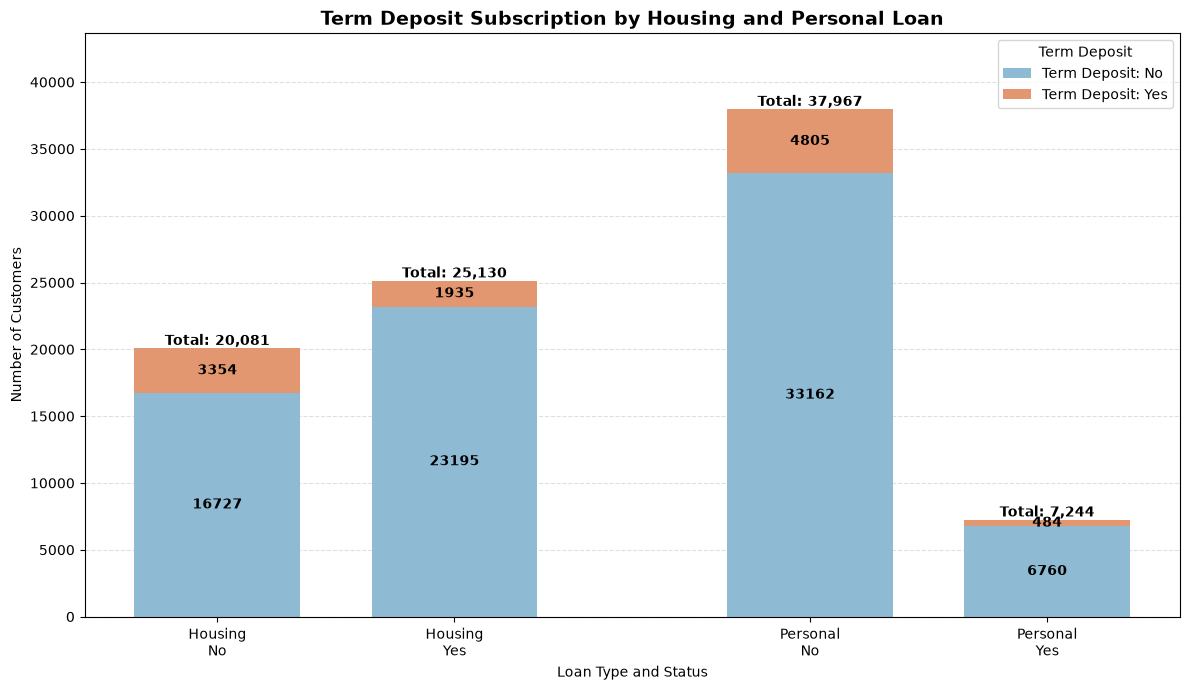

y                         no   yes  total  subscription_rate_pct
              housing                                           
Housing Loan  no       16727  3354  20081                  16.70
              yes      23195  1935  25130                   7.70
Personal Loan no       33162  4805  37967                  12.66
              yes       6760   484   7244                   6.68

In [128]:
housing_counts = pd.crosstab(
    data_full['housing'],
    data_full['y']
).reindex(index=['no', 'yes'], columns=['no', 'yes'], fill_value=0)

personal_counts = pd.crosstab(
    data_full['loan'],
    data_full['y']
).reindex(index=['no', 'yes'], columns=['no', 'yes'], fill_value=0)

# รวมข้อมูลสำหรับสร้างกราฟ
loan_counts = pd.concat(
    [housing_counts, personal_counts],
    keys=['Housing Loan', 'Personal Loan']
)

# =========================================
# 2. สร้าง Stacked Barplot
# =========================================

fig, ax = plt.subplots(figsize=(12, 7))

x = np.array([0, 1, 2.5, 3.5])
width = 0.7

# จำนวนลูกค้าที่ไม่สมัคร
bars_no = ax.bar(
    x,
    loan_counts['no'],
    width=width,
    color='#8fbad4',
    label='Term Deposit: No'
)

# จำนวนลูกค้าที่สมัคร
bars_yes = ax.bar(
    x,
    loan_counts['yes'],
    width=width,
    bottom=loan_counts['no'],
    color='#e39770',
    label='Term Deposit: Yes'
)

# =========================================
# 3. แสดงตัวเลขบนแต่ละ Stack
# =========================================

ax.bar_label(
    bars_no,
    label_type='center',
    fmt='%.0f',
    fontsize=10,
    color='black',
    fontweight='bold'
)

ax.bar_label(
    bars_yes,
    label_type='center',
    fmt='%.0f',
    fontsize=10,
    color='black',
    fontweight='bold'
)

# แสดงจำนวนรวมเหนือแต่ละแท่ง
totals = loan_counts['no'] + loan_counts['yes']

for i, total in enumerate(totals):
    ax.text(
        x[i],
        total + 250,
        f'Total: {total:,}',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

# =========================================
# 4. ปรับแต่งกราฟ
# =========================================

ax.set_xticks(x)
ax.set_xticklabels([
    'Housing\nNo',
    'Housing\nYes',
    'Personal\nNo',
    'Personal\nYes'
])

ax.set_title(
    'Term Deposit Subscription by Housing and Personal Loan',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Loan Type and Status')
ax.set_ylabel('Number of Customers')

ax.set_ylim(0, totals.max() * 1.15)
ax.legend(title='Term Deposit')
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# =========================================
# 5. ตารางสรุปและอัตราการสมัคร
# =========================================

summary = loan_counts.copy()
summary['total'] = summary['no'] + summary['yes']

summary['subscription_rate_pct'] = (
    summary['yes'] / summary['total'] * 100
)

display(summary.round(2))


## Job Category Impact
จงวิเคราะห์ว่าอาชีพใด (job) มีอัตราการสมัคร Term Deposit สูงที่สุด โดยใช้ Barplot แสดงสัดส่วนของลูกค้าที่สมัคร (y = yes) และไม่สมัคร (y = no) ในแต่ละกลุ่มอาชีพ พร้อมอธิบายผลการวิเคราะห์

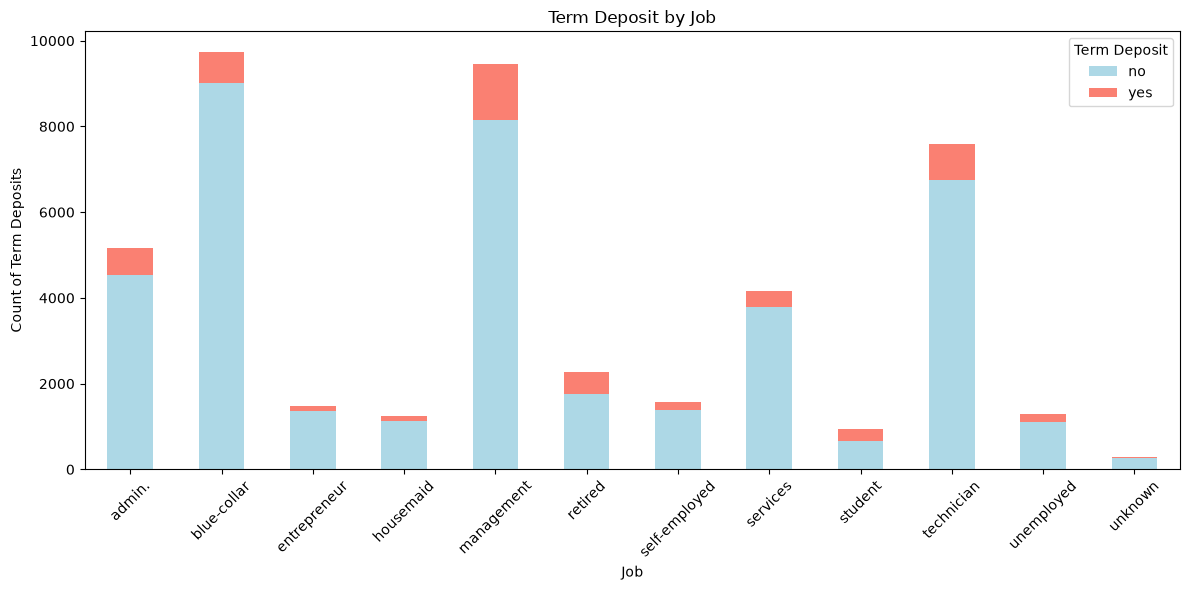

In [129]:
# create bar plot of term deposits by job
plt.figure(figsize=(12, 6))
# Group by job and count the number of term deposits
job_term_deposit_counts = data_full.groupby('job')['y'].value_counts().unstack().fillna(0)
job_term_deposit_counts.plot(kind='bar', stacked=True, color=['lightblue', 'salmon'], ax=plt.gca())
plt.title('Term Deposit by Job')
plt.xlabel('Job')
plt.ylabel('Count of Term Deposits')
plt.xticks(rotation=45)
plt.legend(title='Term Deposit', loc='upper right')
plt.tight_layout()
plt.show()

## Campaign Effectiveness
จงวิเคราะห์ความสัมพันธ์ระหว่างจำนวนครั้งที่ติดต่อลูกค้า (campaign) กับการสมัคร Term Deposit โดยใช้ Scatterplot หรือ Boxplot พร้อมอธิบายว่าการติดต่อลูกค้าหลายครั้งมีความสัมพันธ์กับโอกาสในการสมัครเพิ่มขึ้นหรือไม่

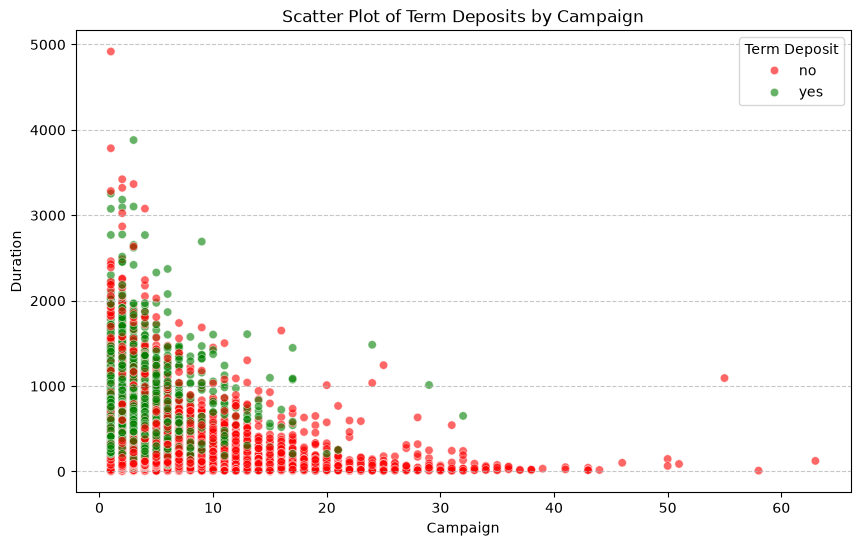

In [130]:
# create scatter plot of term deposits by campaign
plt.figure(figsize=(10, 6))
# Scatter plot of campaign vs. duration, colored by term deposit status
sns.scatterplot(data=data_full, x='campaign', y='duration', hue='y', palette={'yes': 'green', 'no': 'red'}, alpha=0.6)
plt.title('Scatter Plot of Term Deposits by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Duration')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Term Deposit', loc='upper right')
plt.show()

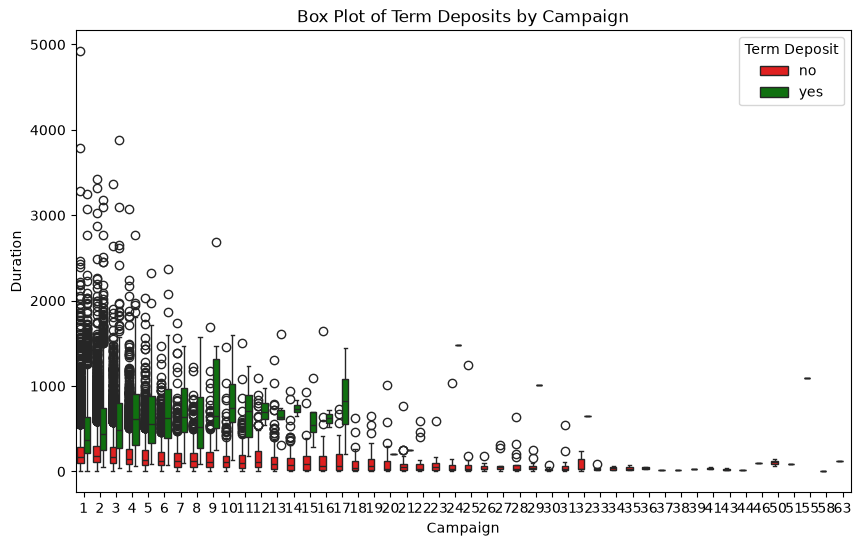

In [131]:
# create box plot of term deposits by campaign
plt.figure(figsize=(10, 6))
sns.boxplot(data=data_full, x='campaign', y='duration', hue='y', palette={'yes': 'green', 'no': 'red'})
plt.title('Box Plot of Term Deposits by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Duration')
plt.legend(title='Term Deposit', loc='upper right')
plt.show()


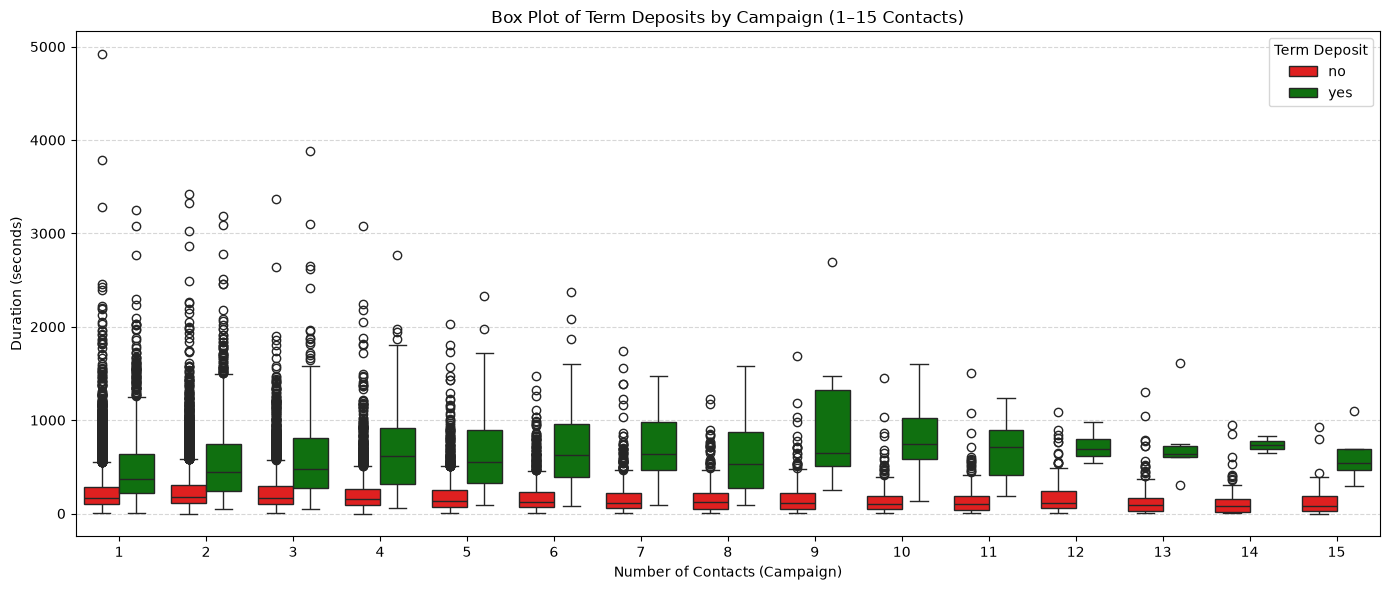

Total records: 45,211
Filtered records: 44,681
Excluded records: 530


In [132]:
# คัดเฉพาะข้อมูลที่ campaign ไม่เกิน 15 ครั้ง
campaign_filtered = data_full[data_full['campaign'] <= 15].copy()

# Create Boxplot of Term Deposits by Campaign
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=campaign_filtered,
    x='campaign',
    y='duration',
    hue='y',
    hue_order=['no', 'yes'],
    palette={'yes': 'green', 'no': 'red'}
)

plt.title('Box Plot of Term Deposits by Campaign (1–15 Contacts)')
plt.xlabel('Number of Contacts (Campaign)')
plt.ylabel('Duration (seconds)')
plt.legend(title='Term Deposit', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# แสดงจำนวนข้อมูลก่อนและหลังกรอง
print(f'Total records: {len(data_full):,}')
print(f'Filtered records: {len(campaign_filtered):,}')
print(f'Excluded records: {len(data_full) - len(campaign_filtered):,}')


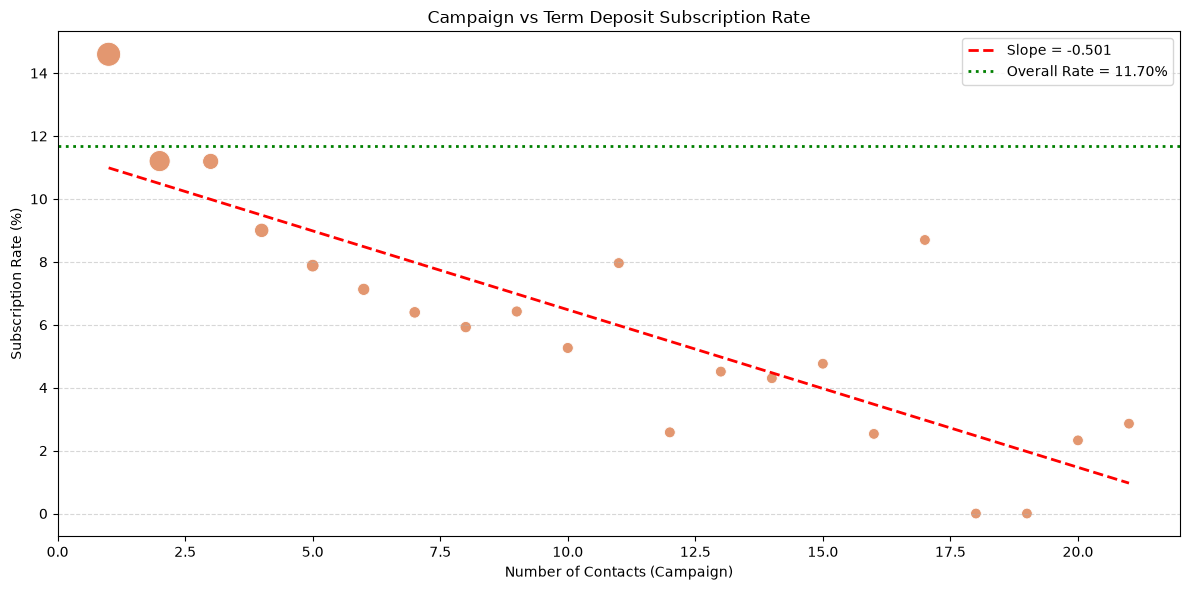

Slope: -0.5011
Intercept: 11.4898
R-squared: 0.6918
P-value: 0.000003


,campaign,Total,Subscribed,Rate (%)
0,1,17544,2561,14.60
1,2,12505,1401,11.20
2,3,5521,618,11.19
3,4,3522,317,9.00
4,5,1764,139,7.88
5,6,1291,92,7.13
6,7,735,47,6.39
7,8,540,32,5.93
8,9,327,21,6.42
9,10,266,14,5.26


In [133]:
# แปลงผลการสมัครเป็นตัวเลข
data_full['subscribed'] = (
    data_full['y'] == 'yes'
).astype(int)

# คำนวณจำนวนลูกค้าและอัตราการสมัคร
campaign_summary = (
    data_full.groupby('campaign')['subscribed']
    .agg(
        Total='count',
        Subscribed='sum',
        Rate='mean'
    )
    .reset_index()
)

campaign_summary['Rate (%)'] = (
    campaign_summary['Rate'] * 100
)

# เลือกกลุ่มที่มีลูกค้าอย่างน้อย 30 คน
plot_data = campaign_summary[
    campaign_summary['Total'] >= 30
].copy()

# คำนวณ Linear Regression
slope, intercept, r_value, p_value, std_err = linregress(
    plot_data['campaign'],
    plot_data['Rate (%)']
)

# สร้าง Scatterplot
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=plot_data,
    x='campaign',
    y='Rate (%)',
    size='Total',
    sizes=(60, 300),
    color='#e39770',
    legend=False
)

# เพิ่มเส้น Slope
x_line = np.linspace(
    plot_data['campaign'].min(),
    plot_data['campaign'].max(),
    100
)

y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Slope = {slope:.3f}'
)

# เส้นอัตราการสมัครเฉลี่ยรวม
overall = data_full['subscribed'].mean() * 100

plt.axhline(
    overall,
    color='green',
    linestyle=':',
    linewidth=2,
    label=f'Overall Rate = {overall:.2f}%'
)

plt.title('Campaign vs Term Deposit Subscription Rate')
plt.xlabel('Number of Contacts (Campaign)')
plt.ylabel('Subscription Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# แสดงผลทางสถิติ
print(f'Slope: {slope:.4f}')
print(f'Intercept: {intercept:.4f}')
print(f'R-squared: {r_value**2:.4f}')
print(f'P-value: {p_value:.6f}')

display(
    plot_data[
        ['campaign', 'Total', 'Subscribed', 'Rate (%)']
    ].round(2)
)


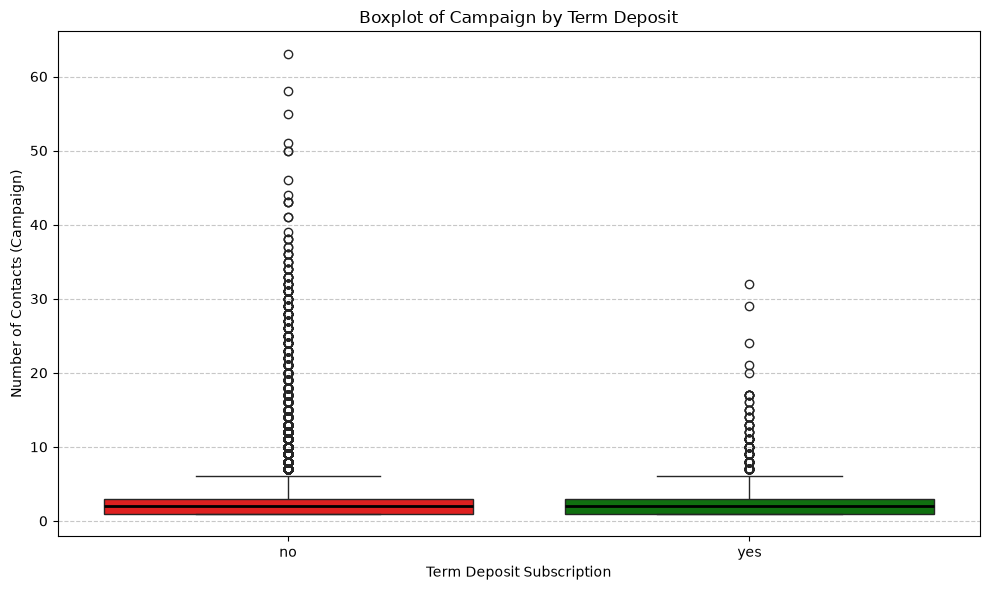

,Term Deposit,Total,Mean,Median,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers,Outlier (%)
0,no,39922,2.85,2.0,1.0,3.0,2.0,-2.0,6.0,2903,7.27
1,yes,5289,2.14,2.0,1.0,3.0,2.0,-2.0,6.0,161,3.04


In [134]:

# Create Boxplot of Campaign by Term Deposit
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=data_full,
    x='y',
    y='campaign',
    order=['no', 'yes'],
    hue='y',
    palette={'yes': 'green', 'no': 'red'},
    legend=False,
    medianprops=dict(color='black', linewidth=2),
    ax=ax
)

ax.set_title('Boxplot of Campaign by Term Deposit')
ax.set_xlabel('Term Deposit Subscription')
ax.set_ylabel('Number of Contacts (Campaign)')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# ==========================================
# Calculate Statistics & Outliers by Group
# ==========================================

results = []

for group in ['no', 'yes']:

    campaign = data_full.loc[
        data_full['y'] == group,
        'campaign'
    ].dropna()

    # คำนวณค่าสถิติ
    mean = campaign.mean()
    median = campaign.median()

    Q1 = campaign.quantile(0.25)
    Q3 = campaign.quantile(0.75)
    IQR = Q3 - Q1

    # คำนวณขอบเขต Outliers
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # หาค่า Outliers
    outliers = campaign[
        (campaign < lower_fence) |
        (campaign > upper_fence)
    ]

    outlier_count = len(outliers)
    outlier_pct = (
        outlier_count / len(campaign)
    ) * 100

    results.append({
        'Term Deposit': group,
        'Total': len(campaign),
        'Mean': mean,
        'Median': median,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Fence': lower_fence,
        'Upper Fence': upper_fence,
        'Outliers': outlier_count,
        'Outlier (%)': outlier_pct
    })

# แสดงตารางสถิติ
campaign_stats = pd.DataFrame(results)

display(campaign_stats.round(2))


## Previous Outcome Influence
จงวิเคราะห์ผลลัพธ์ของแคมเปญก่อนหน้า (poutcome) ที่มีความสัมพันธ์กับการสมัคร Term Deposit ในปัจจุบัน โดยใช้ Barplot เปรียบเทียบอัตราการสมัครของลูกค้าในแต่ละกลุ่ม ได้แก่ success, failure, other และ unknown พร้อมสรุปข้อค้นพบ (Insights) จากการวิเคราะห์

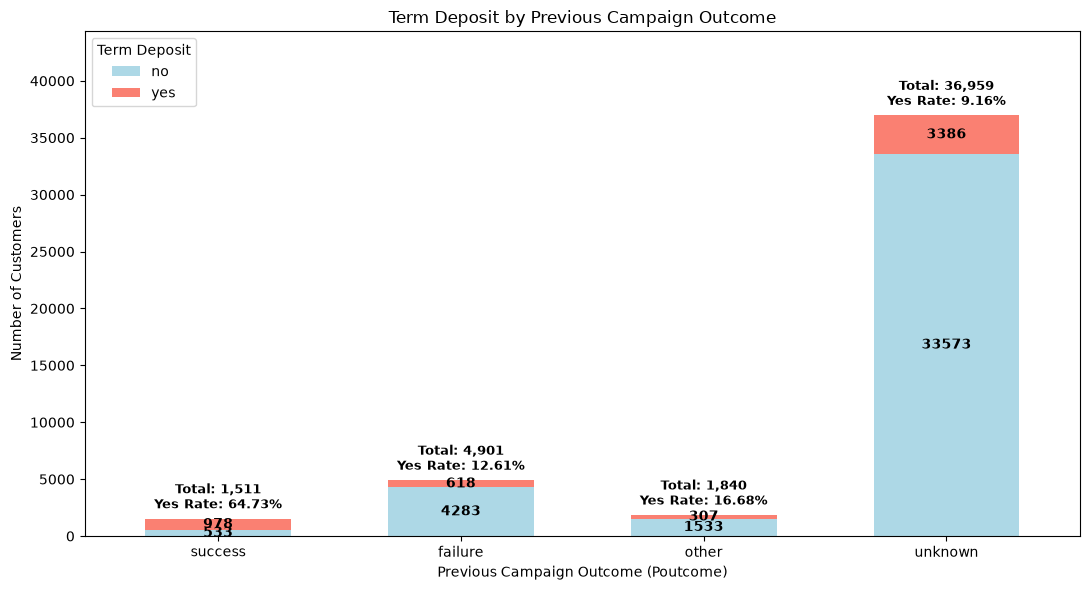

y,no,yes,Total,Subscription Rate (%)
poutcome,,,,
success,533,978,1511,64.73
failure,4283,618,4901,12.61
other,1533,307,1840,16.68
unknown,33573,3386,36959,9.16


In [146]:
# Create Crosstab of Poutcome and Term Deposit
poutcome_term_deposit_counts = pd.crosstab(
    data_full['poutcome'],
    data_full['y']
)

# กำหนดลำดับกลุ่มและผลการสมัคร
poutcome_term_deposit_counts = (
    poutcome_term_deposit_counts.reindex(
        index=['success', 'failure', 'other', 'unknown'],
        columns=['no', 'yes'],
        fill_value=0
    )
)

# คำนวณจำนวนรวมและอัตราการสมัคร
total = poutcome_term_deposit_counts.sum(axis=1)

subscription_rate = (
    poutcome_term_deposit_counts['yes'] / total * 100
)

# Create Stacked Barplot
fig, ax = plt.subplots(figsize=(11, 6))

poutcome_term_deposit_counts.plot(
    kind='bar',
    stacked=True,
    color=['lightblue', 'salmon'],
    ax=ax,
    width=0.6
)

# เพิ่มตัวเลขจำนวนคนในแต่ละส่วนของแท่งกราฟ
for container in ax.containers:
    ax.bar_label(
        container,
        label_type='center',
        fmt='%.0f',
        fontsize=10,
        fontweight='bold',
        color='black'
    )

# เพิ่มจำนวนรวมและอัตราการสมัครเหนือแท่งกราฟ
for i, group in enumerate(poutcome_term_deposit_counts.index):
    ax.text(
        i,
        total.loc[group] + total.max() * 0.015,
        f'Total: {total.loc[group]:,}\n'
        f'Yes Rate: {subscription_rate.loc[group]:.2f}%',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.title('Term Deposit by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome (Poutcome)')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(title='Term Deposit', loc='upper left')

# เพิ่มพื้นที่ด้านบนสำหรับตัวเลข
ax.set_ylim(0, total.max() * 1.20)

plt.tight_layout()
plt.show()

# ตารางสรุป
summary = poutcome_term_deposit_counts.copy()
summary['Total'] = total
summary['Subscription Rate (%)'] = subscription_rate

display(summary.round(2))


# ส่วนที่ 2: Hypothesis-Based EDA

## Duration Effect
สมมติฐาน: ลูกค้าที่ใช้เวลาในการสนทนา (duration) นานกว่าจะมีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่ใช้เวลาในการสนทนาสั้นกว่า
การพิสูจน์สมมติฐาน: จงสร้าง Boxplot หรือ Histogram แสดงการกระจายของตัวแปร duration โดยแยกตามผลการสมัคร (y = yes/no) พร้อมวิเคราะห์และอธิบายว่าข้อมูลสนับสนุนสมมติฐานดังกล่าวหรือไม่

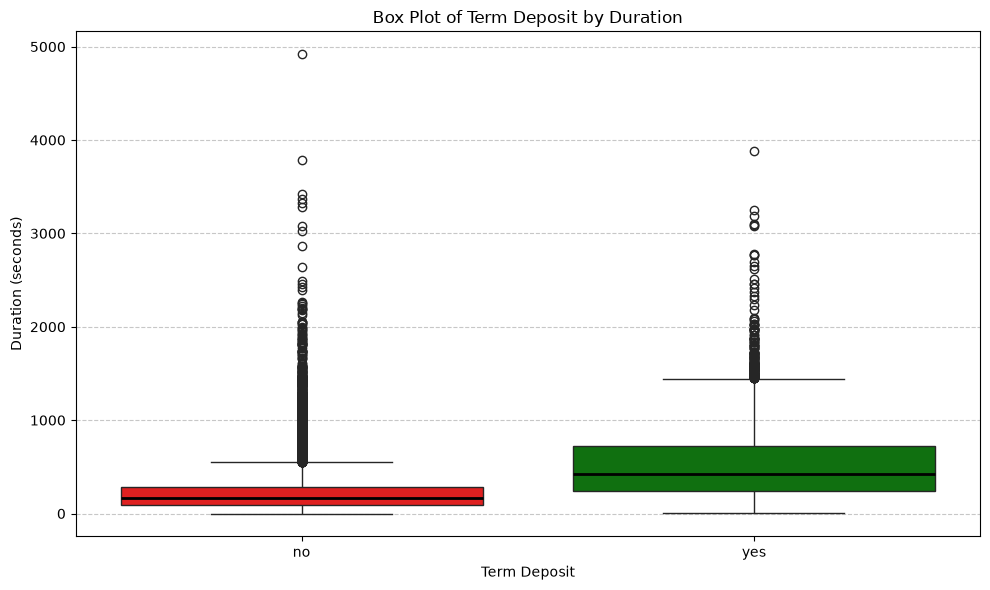

,Term Deposit,Total,Median,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers,Outlier (%)
0,no,39922,164.0,95.0,279.0,184.0,-181.0,555.0,2384,5.97
1,yes,5289,426.0,244.0,725.0,481.0,-477.5,1446.5,167,3.16


In [136]:
# Create Boxplot of Term Deposit by Duration
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data_full,
    x='y',
    y='duration',
    order=['no', 'yes'],
    hue='y',
    palette={'yes': 'green', 'no': 'red'},
    legend=False,
    medianprops=dict(color='black', linewidth=2)
)

plt.title('Box Plot of Term Deposit by Duration')
plt.xlabel('Term Deposit')
plt.ylabel('Duration (seconds)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# =====================================
# Calculate Statistics and Outliers
# =====================================

results = []

for group in ['no', 'yes']:

    # เลือกข้อมูล Duration ของแต่ละกลุ่ม
    duration = data_full.loc[
        data_full['y'] == group, 'duration'
    ].dropna()

    # คำนวณค่าสถิติ
    median = duration.median()
    Q1 = duration.quantile(0.25)
    Q3 = duration.quantile(0.75)
    IQR = Q3 - Q1

    # คำนวณขอบเขต Outliers (IQR Method)
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # ตรวจสอบ Outliers
    outliers = duration[
        (duration < lower_fence) |
        (duration > upper_fence)
    ]

    outlier_count = len(outliers)
    outlier_pct = (outlier_count / len(duration)) * 100

    # บันทึกผลลัพธ์
    results.append({
        'Term Deposit': group,
        'Total': len(duration),
        'Median': median,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Fence': lower_fence,
        'Upper Fence': upper_fence,
        'Outliers': outlier_count,
        'Outlier (%)': outlier_pct
    })

# สร้างตารางสรุป
duration_summary = pd.DataFrame(results)

display(duration_summary.round(2))


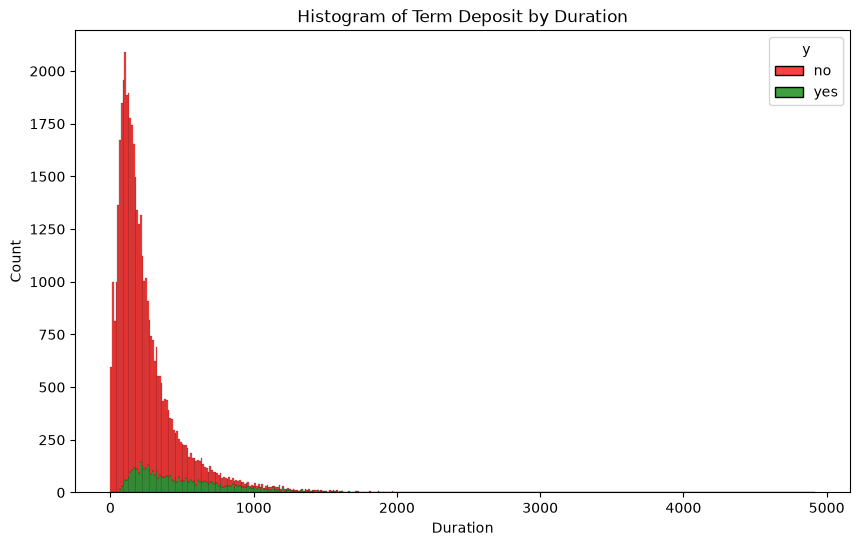

In [137]:
# create histogram of Term Deposit by duration
plt.figure(figsize=(10, 6))
sns.histplot(data=data_full, x='duration', hue='y', multiple='stack', palette={'yes': 'green', 'no': 'red'})
plt.title('Histogram of Term Deposit by Duration')
plt.xlabel('Duration')
plt.ylabel('Count')
plt.show()


## Education Impact
สมมติฐาน: ลูกค้าที่มีการศึกษาระดับอุดมศึกษา (tertiary) มีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่มีการศึกษาระดับอื่น
การพิสูจน์สมมติฐาน: จงสร้าง Barplot แสดงสัดส่วนการสมัคร (y = yes) ในแต่ละระดับการศึกษา (education) พร้อมเปรียบเทียบและอธิบายว่าผลการวิเคราะห์สอดคล้องกับสมมติฐานดังกล่าวหรือไม่

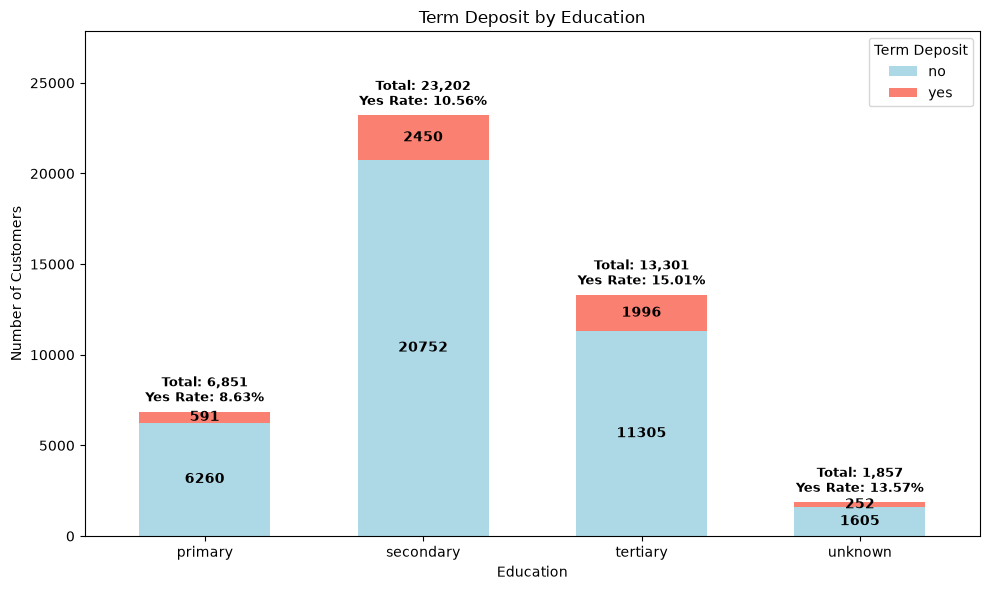

y,no,yes,Total,Subscription Rate (%)
education,,,,
primary,6260,591,6851,8.63
secondary,20752,2450,23202,10.56
tertiary,11305,1996,13301,15.01
unknown,1605,252,1857,13.57


In [138]:
# Create Crosstab of Education and Term Deposit
education_term_deposit_counts = pd.crosstab(
    data_full['education'],
    data_full['y']
)

# กำหนดลำดับระดับการศึกษาและผลการสมัคร
education_term_deposit_counts = (
    education_term_deposit_counts.reindex(
        index=['primary', 'secondary', 'tertiary', 'unknown'],
        columns=['no', 'yes'],
        fill_value=0
    )
)

# คำนวณจำนวนรวมและอัตราการสมัคร
total = education_term_deposit_counts.sum(axis=1)
subscription_rate = (
    education_term_deposit_counts['yes'] / total * 100
)

# Create Stacked Barplot
fig, ax = plt.subplots(figsize=(10, 6))

education_term_deposit_counts.plot(
    kind='bar',
    stacked=True,
    color=['lightblue', 'salmon'],
    ax=ax,
    width=0.6
)

# แสดงจำนวนลูกค้าบนแต่ละส่วนของแท่งกราฟ
for container in ax.containers:
    ax.bar_label(
        container,
        label_type='center',
        fmt='%.0f',
        fontsize=10,
        fontweight='bold',
        color='black'
    )

# แสดงจำนวนรวมและอัตราการสมัครเหนือแท่งกราฟ
for i, group in enumerate(education_term_deposit_counts.index):
    ax.text(
        i,
        total.loc[group] + total.max() * 0.015,
        f'Total: {total.loc[group]:,}\n'
        f'Yes Rate: {subscription_rate.loc[group]:.2f}%',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.title('Term Deposit by Education')
plt.xlabel('Education')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(title='Term Deposit', loc='upper right')

# เพิ่มพื้นที่ด้านบนให้ตัวเลขไม่ถูกตัด
ax.set_ylim(0, total.max() * 1.20)

plt.tight_layout()
plt.show()

# ตารางสรุป
summary = education_term_deposit_counts.copy()
summary['Total'] = total
summary['Subscription Rate (%)'] = subscription_rate

display(summary.round(2))


## Loan Constraint
สมมติฐาน: ลูกค้าที่มีสินเชื่อส่วนบุคคล (loan = yes) มีแนวโน้มสมัคร Term Deposit น้อยกว่าลูกค้าที่ไม่มีสินเชื่อส่วนบุคคล (loan = no)
การพิสูจน์สมมติฐาน: จงสร้าง Stacked Barplot หรือตารางไขว้ (Crosstab Table) เพื่อเปรียบเทียบสัดส่วนการสมัคร (y = yes/no) ระหว่างกลุ่มลูกค้าที่มีและไม่มีสินเชื่อส่วนบุคคล พร้อมวิเคราะห์และอธิบายว่าข้อมูลสนับสนุนสมมติฐานดังกล่าวหรือไม่

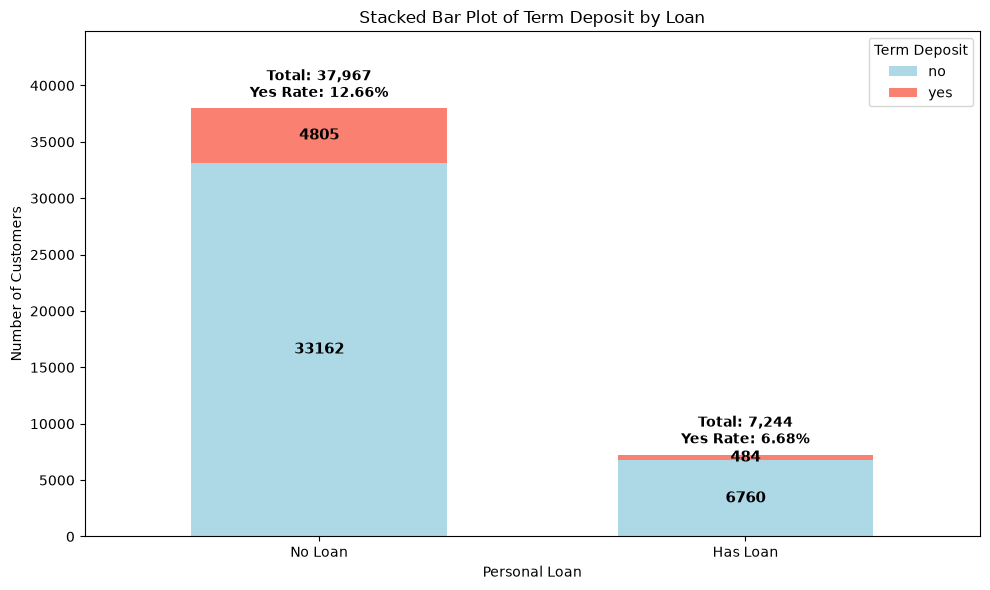

y,no,yes,Total,Subscription Rate (%)
loan,,,,
no,33162,4805,37967,12.66
yes,6760,484,7244,6.68


In [139]:
# Create Crosstab of Loan and Term Deposit
loan_term_deposit_crosstab = pd.crosstab(
    data_full['loan'],
    data_full['y']
)

# กำหนดลำดับข้อมูล
loan_term_deposit_crosstab = (
    loan_term_deposit_crosstab
    .reindex(index=['no', 'yes'], columns=['no', 'yes'], fill_value=0)
)

# คำนวณจำนวนรวมและอัตราการสมัคร
total = loan_term_deposit_crosstab.sum(axis=1)
subscription_rate = (
    loan_term_deposit_crosstab['yes'] / total * 100
)

# Create Stacked Barplot
fig, ax = plt.subplots(figsize=(10, 6))

loan_term_deposit_crosstab.plot(
    kind='bar',
    stacked=True,
    color=['lightblue', 'salmon'],
    ax=ax,
    width=0.6
)

# เพิ่มจำนวนคนบนแต่ละส่วนของแท่งกราฟ
for container in ax.containers:
    ax.bar_label(
        container,
        label_type='center',
        fmt='%.0f',
        fontsize=11,
        fontweight='bold',
        color='black'
    )

# เพิ่มจำนวนรวมและอัตราการสมัครเหนือแท่งกราฟ
for i, group in enumerate(loan_term_deposit_crosstab.index):

    ax.text(
        i,
        total.loc[group] + 600,
        f'Total: {total.loc[group]:,}\n'
        f'Yes Rate: {subscription_rate.loc[group]:.2f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title('Stacked Bar Plot of Term Deposit by Loan')
ax.set_xlabel('Personal Loan')
ax.set_ylabel('Number of Customers')

ax.set_xticklabels(['No Loan', 'Has Loan'], rotation=0)
ax.legend(title='Term Deposit', loc='upper right')

# เพิ่มพื้นที่สำหรับตัวเลขด้านบน
ax.set_ylim(0, total.max() * 1.18)

plt.tight_layout()
plt.show()

# ตารางสรุป
summary = loan_term_deposit_crosstab.copy()
summary['Total'] = total
summary['Subscription Rate (%)'] = subscription_rate

display(summary.round(2))


In [147]:

# Create Crosstab of Loan and Term Deposit
loan_crosstab = pd.crosstab(
    data_full['loan'],
    data_full['y']
)

# กำหนดลำดับแถวและคอลัมน์
loan_crosstab = loan_crosstab.reindex(
    index=['no', 'yes'],
    columns=['no', 'yes'],
    fill_value=0
)

# ==================================
# 1. Crosstab Table: Count
# ==================================

count_table = loan_crosstab.copy()

count_table['Total'] = count_table.sum(axis=1)

print('Crosstab Table: Loan vs Term Deposit (Count)')
display(count_table)

# ==================================
# 2. Crosstab Table: Percentage
# ==================================

percentage_table = loan_crosstab.div(
    loan_crosstab.sum(axis=1),
    axis=0
) * 100

print('Crosstab Table: Loan vs Term Deposit (%)')
display(percentage_table.round(2))

# ==================================
# 3. Summary Table: Count and Rate
# ==================================

summary = loan_crosstab.copy()

summary['Total'] = summary['no'] + summary['yes']

summary['No Rate (%)'] = (
    summary['no'] / summary['Total'] * 100
)

summary['Yes Rate (%)'] = (
    summary['yes'] / summary['Total'] * 100
)

summary.index = ['No Loan', 'Has Loan']

print('Summary: Loan vs Term Deposit')
display(summary.round(2))


Crosstab Table: Loan vs Term Deposit (Count)


y,no,yes,Total
loan,,,
no,33162,4805,37967
yes,6760,484,7244


Crosstab Table: Loan vs Term Deposit (%)


y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


Summary: Loan vs Term Deposit


y,no,yes,Total,No Rate (%),Yes Rate (%)
No Loan,33162,4805,37967,87.34,12.66
Has Loan,6760,484,7244,93.32,6.68


## Contact Method Effect
สมมติฐาน: ลูกค้าที่ได้รับการติดต่อผ่านโทรศัพท์มือถือ (contact = cellular) มีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่ได้รับการติดต่อผ่านโทรศัพท์พื้นฐาน (contact = telephone)
การพิสูจน์สมมติฐาน: จงสร้าง Barplot เปรียบเทียบสัดส่วนการสมัคร (y = yes) ระหว่างกลุ่มลูกค้าที่ได้รับการติดต่อผ่าน cellular และ telephone พร้อมวิเคราะห์และอธิบายว่าผลการวิเคราะห์สอดคล้องกับสมมติฐานดังกล่าวหรือไม่

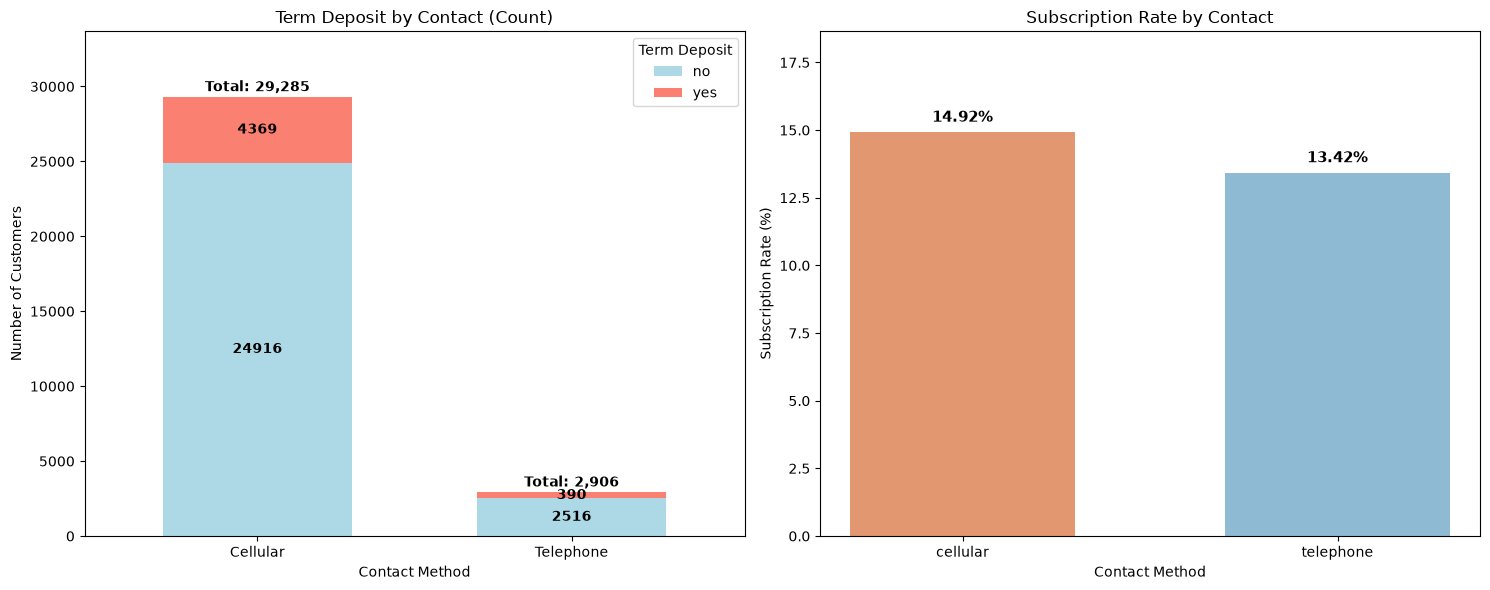

y,no,yes,Total,Subscription Rate (%)
contact,,,,
cellular,24916,4369,29285,14.92
telephone,2516,390,2906,13.42


Cellular Subscription Rate: 14.92%
Telephone Subscription Rate: 13.42%
Difference: 1.50 percentage points


In [140]:
# เลือกเฉพาะ cellular และ telephone
contact_data = data_full[
    data_full['contact'].isin(['cellular', 'telephone'])
].copy()

# สร้าง Crosstab จำนวนลูกค้า
contact_counts = pd.crosstab(
    contact_data['contact'],
    contact_data['y']
).reindex(
    index=['cellular', 'telephone'],
    columns=['no', 'yes'],
    fill_value=0
)

# คำนวณจำนวนรวมและอัตราการสมัคร
total = contact_counts.sum(axis=1)
subscription_rate = contact_counts['yes'] / total * 100

# สร้างกราฟ 2 รูป
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# ===================================
# กราฟซ้าย: Stacked Barplot (Count)
# ===================================
contact_counts.plot(
    kind='bar',
    stacked=True,
    color=['lightblue', 'salmon'],
    width=0.6,
    ax=ax[0]
)

# จำนวนบนแต่ละส่วนของแท่ง
for container in ax[0].containers:
    ax[0].bar_label(
        container,
        label_type='center',
        fmt='%.0f',
        fontsize=10,
        fontweight='bold'
    )

# จำนวนรวมบนแท่ง
for i, group in enumerate(contact_counts.index):
    ax[0].text(
        i,
        total.loc[group] + 400,
        f'Total: {total.loc[group]:,}',
        ha='center',
        fontweight='bold'
    )

ax[0].set_title('Term Deposit by Contact (Count)')
ax[0].set_xlabel('Contact Method')
ax[0].set_ylabel('Number of Customers')
ax[0].set_xticklabels(
    ['Cellular', 'Telephone'], rotation=0
)
ax[0].set_ylim(0, total.max() * 1.15)
ax[0].legend(title='Term Deposit')

# ===================================
# กราฟขวา: Subscription Rate (%)
# ===================================
bars = ax[1].bar(
    subscription_rate.index,
    subscription_rate.values,
    color=['#e39770', '#8fbad4'],
    width=0.6
)

# แสดงเปอร์เซ็นต์บนแท่ง
ax[1].bar_label(
    bars,
    fmt='%.2f%%',
    padding=5,
    fontsize=11,
    fontweight='bold'
)

ax[1].set_title('Subscription Rate by Contact')
ax[1].set_xlabel('Contact Method')
ax[1].set_ylabel('Subscription Rate (%)')
ax[1].set_ylim(0, subscription_rate.max() * 1.25)

plt.tight_layout()
plt.show()

# ===================================
# ตารางสรุป
# ===================================
summary = contact_counts.copy()
summary['Total'] = total
summary['Subscription Rate (%)'] = subscription_rate

display(summary.round(2))

# เปรียบเทียบอัตราการสมัคร
difference = (
    subscription_rate['cellular']
    - subscription_rate['telephone']
)

print(f'Cellular Subscription Rate: {subscription_rate["cellular"]:.2f}%')
print(f'Telephone Subscription Rate: {subscription_rate["telephone"]:.2f}%')
print(f'Difference: {difference:.2f} percentage points')


## Campaign Timing Effect
สมมติฐาน: ลูกค้าที่ได้รับการติดต่อจำนวนน้อยครั้ง (campaign มีค่าต่ำ) มีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่ได้รับการติดต่อหลายครั้ง (campaign มีค่าสูง)
การพิสูจน์สมมติฐาน: จงสร้าง Boxplot หรือ Scatterplot แสดงความสัมพันธ์ระหว่างจำนวนครั้งที่ติดต่อลูกค้า (campaign) กับผลการสมัคร (y) พร้อมวิเคราะห์และอธิบายว่าข้อมูลสนับสนุนสมมติฐานดังกล่าวหรือไม่

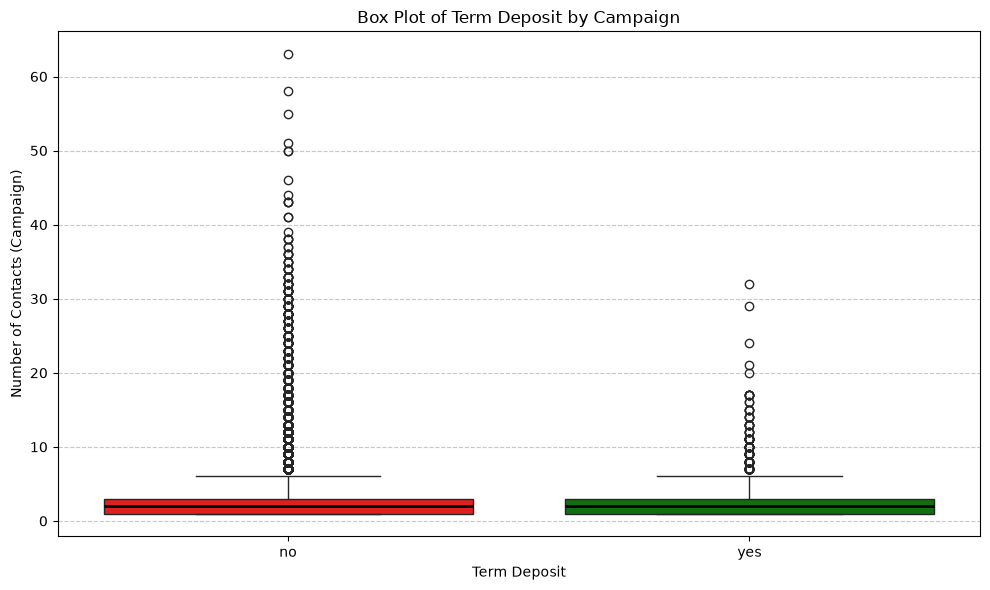

,Term Deposit,Total,Mean,Median,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers,Outlier (%)
0,no,39922,2.85,2.0,1.0,3.0,2.0,-2.0,6.0,2903,7.27
1,yes,5289,2.14,2.0,1.0,3.0,2.0,-2.0,6.0,161,3.04


Mean Campaign (No): 2.85
Mean Campaign (Yes): 2.14
Conclusion: Descriptive results support the hypothesis.


In [141]:
# Create Boxplot of Term Deposit by Campaign
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data_full,
    x='y',
    y='campaign',
    order=['no', 'yes'],
    hue='y',
    palette={'yes': 'green', 'no': 'red'},
    legend=False,
    medianprops=dict(color='black', linewidth=2)
)

plt.title('Box Plot of Term Deposit by Campaign')
plt.xlabel('Term Deposit')
plt.ylabel('Number of Contacts (Campaign)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# =====================================
# Calculate Statistics and Outliers
# =====================================

results = []

for group in ['no', 'yes']:

    # เลือกข้อมูลแต่ละกลุ่ม
    campaign = data_full.loc[
        data_full['y'] == group, 'campaign'
    ].dropna()

    # คำนวณค่าสถิติ
    mean = campaign.mean()
    median = campaign.median()

    Q1 = campaign.quantile(0.25)
    Q3 = campaign.quantile(0.75)

    IQR = Q3 - Q1

    # คำนวณขอบเขต Outliers
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # ตรวจสอบ Outliers
    outliers = campaign[
        (campaign < lower_fence) |
        (campaign > upper_fence)
    ]

    outlier_count = len(outliers)
    outlier_pct = outlier_count / len(campaign) * 100

    # เก็บผลลัพธ์
    results.append({
        'Term Deposit': group,
        'Total': len(campaign),
        'Mean': mean,
        'Median': median,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Fence': lower_fence,
        'Upper Fence': upper_fence,
        'Outliers': outlier_count,
        'Outlier (%)': outlier_pct
    })

# สร้างตารางสรุป
campaign_summary = pd.DataFrame(results)

display(campaign_summary.round(2))

# =====================================
# Hypothesis Conclusion
# =====================================

mean_no = campaign_summary.loc[
    campaign_summary['Term Deposit'] == 'no', 'Mean'
].iloc[0]

mean_yes = campaign_summary.loc[
    campaign_summary['Term Deposit'] == 'yes', 'Mean'
].iloc[0]

print(f'Mean Campaign (No): {mean_no:.2f}')
print(f'Mean Campaign (Yes): {mean_yes:.2f}')

if mean_yes < mean_no:
    print('Conclusion: Descriptive results support the hypothesis.')
else:
    print('Conclusion: Descriptive results do not support the hypothesis.')


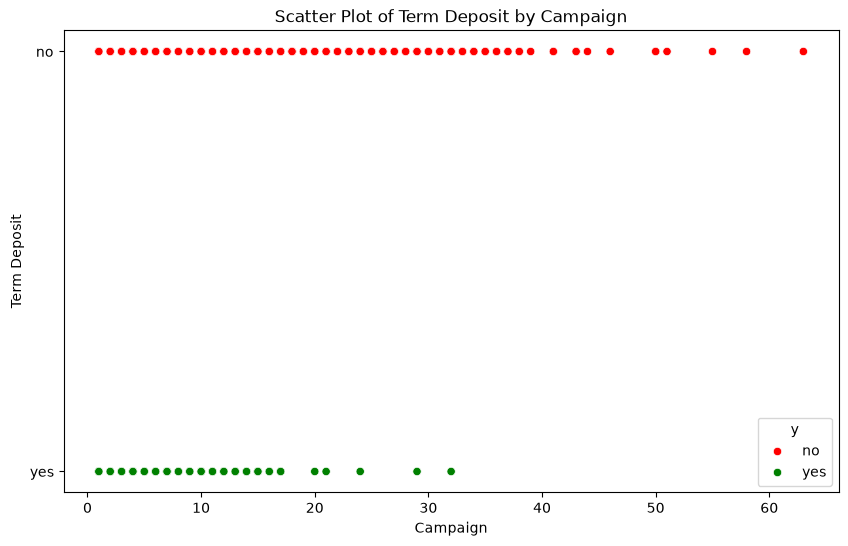

In [142]:
# create scatter plot of Term Deposit by campaign
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data_full, x='campaign', y='y', hue='y', palette={'yes': 'green', 'no': 'red'})
plt.title('Scatter Plot of Term Deposit by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Term Deposit')
plt.show()


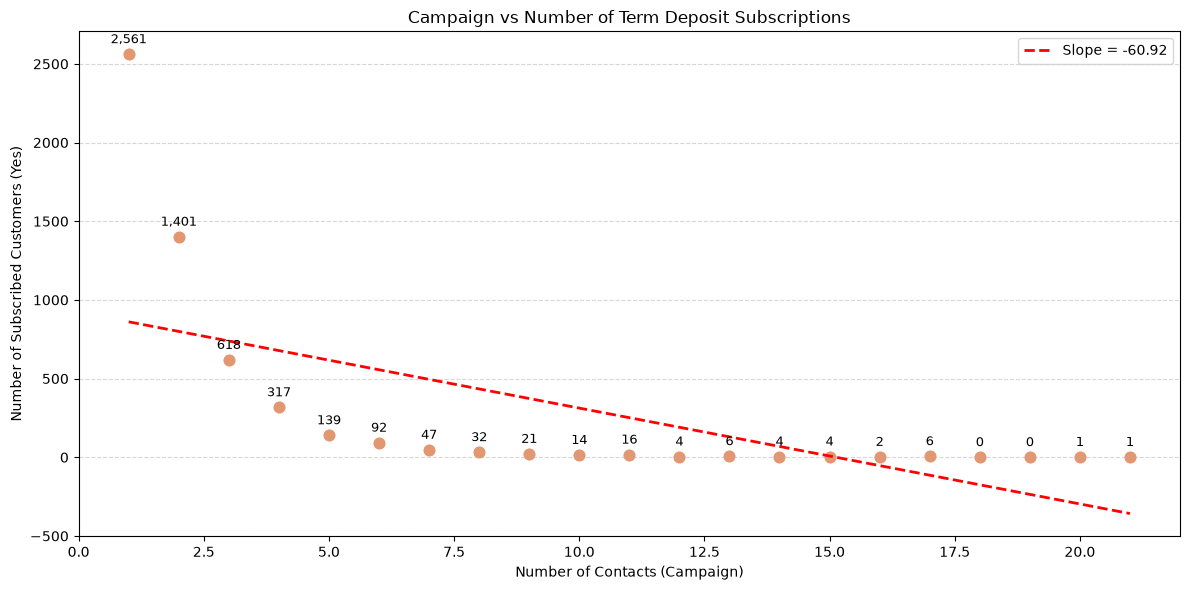

Slope: -60.9182
R-squared: 0.3708
P-value: 0.003390


,campaign,Total,Subscribed,Rate (%)
0,1,17544,2561,14.60
1,2,12505,1401,11.20
2,3,5521,618,11.19
3,4,3522,317,9.00
4,5,1764,139,7.88
5,6,1291,92,7.13
6,7,735,47,6.39
7,8,540,32,5.93
8,9,327,21,6.42
9,10,266,14,5.26


In [143]:
# แปลง y เป็นตัวเลข
data_full['subscribed'] = (
    data_full['y'] == 'yes'
).astype(int)

# นับจำนวนลูกค้าที่สมัครและจำนวนลูกค้าทั้งหมด
campaign_summary = (
    data_full.groupby('campaign')['subscribed']
    .agg(
        Total='count',
        Subscribed='sum'
    )
    .reset_index()
)

# คำนวณอัตราการสมัคร
campaign_summary['Rate (%)'] = (
    campaign_summary['Subscribed'] /
    campaign_summary['Total'] * 100
)

# เลือกเฉพาะ campaign ที่มีลูกค้าอย่างน้อย 30 คน
plot_data = campaign_summary[
    campaign_summary['Total'] >= 30
].copy()

# คำนวณ Linear Regression ของจำนวนผู้สมัคร
slope, intercept, r_value, p_value, std_err = linregress(
    plot_data['campaign'],
    plot_data['Subscribed']
)

# สร้าง Scatterplot
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=plot_data,
    x='campaign',
    y='Subscribed',
    color='#e39770',
    s=90
)

# เส้น Linear Regression
x_line = np.linspace(
    plot_data['campaign'].min(),
    plot_data['campaign'].max(),
    100
)

y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Slope = {slope:.2f}'
)

# เพิ่มจำนวนผู้สมัครบนจุด
for _, row in plot_data.iterrows():
    plt.annotate(
        f"{int(row['Subscribed']):,}",
        (row['campaign'], row['Subscribed']),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

plt.title('Campaign vs Number of Term Deposit Subscriptions')
plt.xlabel('Number of Contacts (Campaign)')
plt.ylabel('Number of Subscribed Customers (Yes)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

print(f'Slope: {slope:.4f}')
print(f'R-squared: {r_value**2:.4f}')
print(f'P-value: {p_value:.6f}')

display(campaign_summary.round(2))


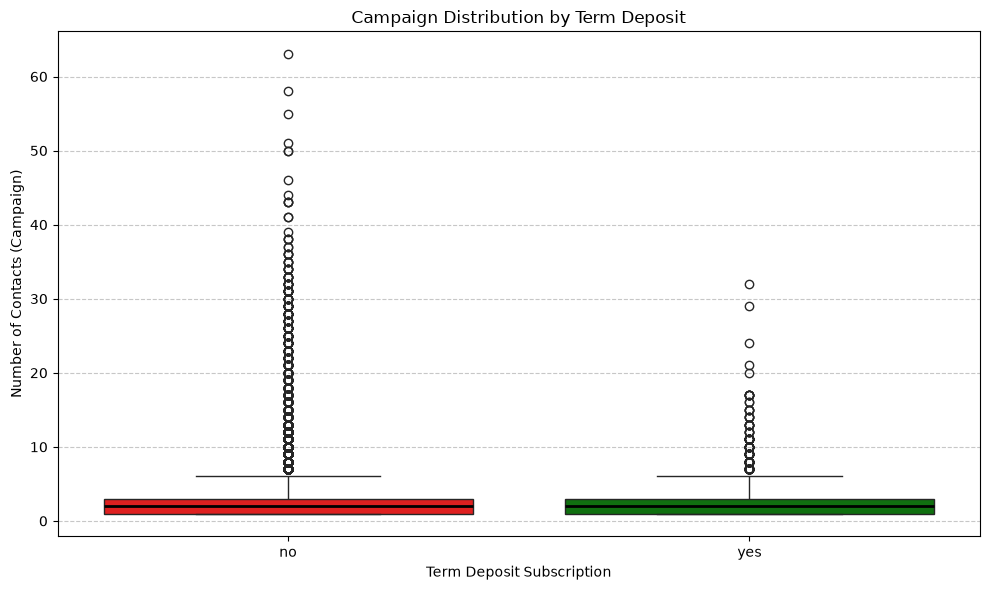

,Term Deposit,Total,Mean,Median,Q1,Q3,IQR,Lower Fence,Upper Fence,Outliers,Outlier (%)
0,no,39922,2.85,2.0,1.0,3.0,2.0,-2.0,6.0,2903,7.27
1,yes,5289,2.14,2.0,1.0,3.0,2.0,-2.0,6.0,161,3.04


In [144]:
# Create Boxplot of Campaign by Term Deposit
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data_full,
    x='y',
    y='campaign',
    order=['no', 'yes'],
    hue='y',
    palette={'no': 'red', 'yes': 'green'},
    legend=False,
    medianprops=dict(color='black', linewidth=2)
)

plt.title('Campaign Distribution by Term Deposit')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Number of Contacts (Campaign)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# คำนวณสถิติแยกตามกลุ่ม
results = []

for group in ['no', 'yes']:

    campaign = data_full.loc[
        data_full['y'] == group,
        'campaign'
    ].dropna()

    mean = campaign.mean()
    median = campaign.median()
    Q1 = campaign.quantile(0.25)
    Q3 = campaign.quantile(0.75)
    IQR = Q3 - Q1

    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    outliers = campaign[
        (campaign < lower_fence) |
        (campaign > upper_fence)
    ]

    results.append({
        'Term Deposit': group,
        'Total': len(campaign),
        'Mean': mean,
        'Median': median,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Fence': lower_fence,
        'Upper Fence': upper_fence,
        'Outliers': len(outliers),
        'Outlier (%)': len(outliers) / len(campaign) * 100
    })

campaign_stats = pd.DataFrame(results)

display(campaign_stats.round(2))


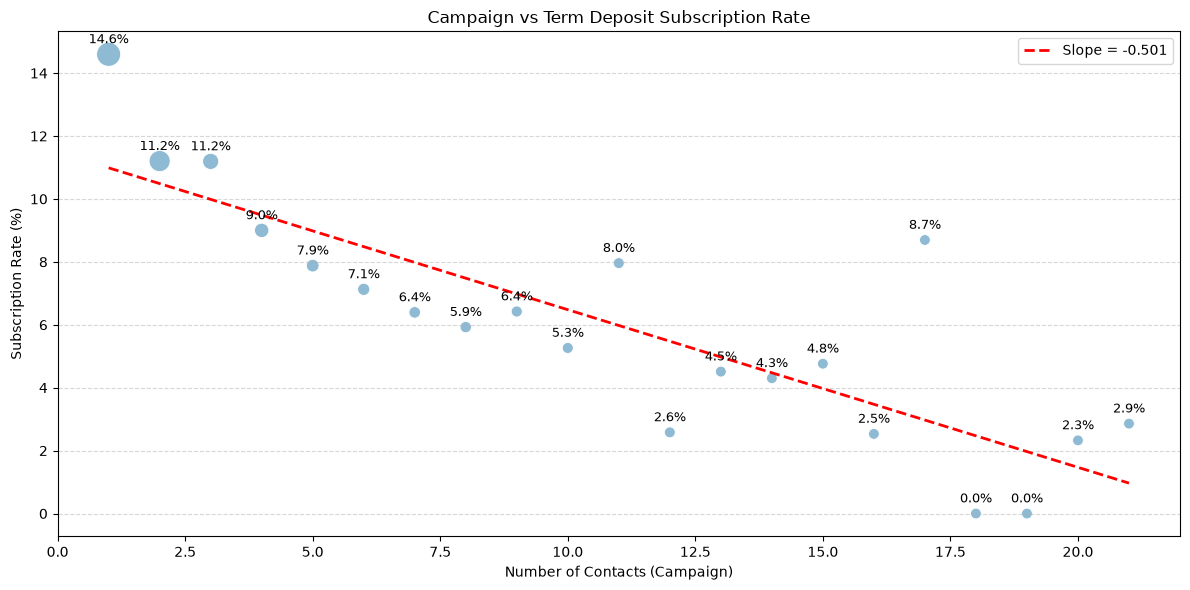

Rate Slope: -0.5011
Rate R-squared: 0.6918


In [145]:
# คำนวณเส้นแนวโน้มอัตราการสมัคร
rate_slope, rate_intercept, rate_r, rate_p, _ = linregress(
    plot_data['campaign'],
    plot_data['Rate (%)']
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=plot_data,
    x='campaign',
    y='Rate (%)',
    size='Total',
    sizes=(60, 300),
    color='#8fbad4',
    legend=False
)

# เพิ่มเส้น slope
plt.plot(
    x_line,
    rate_slope * x_line + rate_intercept,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Slope = {rate_slope:.3f}'
)

# แสดงค่าเปอร์เซ็นต์บนจุด
for _, row in plot_data.iterrows():
    plt.annotate(
        f"{row['Rate (%)']:.1f}%",
        (row['campaign'], row['Rate (%)']),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

plt.title('Campaign vs Term Deposit Subscription Rate')
plt.xlabel('Number of Contacts (Campaign)')
plt.ylabel('Subscription Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

print(f'Rate Slope: {rate_slope:.4f}')
print(f'Rate R-squared: {rate_r**2:.4f}')
